# BT4012 Group 6 — Data Sampling, Cleaning & Evaluation Framework

**Dataset:** Home Credit Default Risk (Kaggle). 7 relational tables, 307,511 labelled applicants.

This notebook prepares **one shared, clean dataset** for all three experiments and the **evaluation framework**
they all use. Feature engineering is left to each experiment owner.

| Part | What it does | Output |
|---|---|---|
| 1. Setup | imports, paths, settings | — |
| 2. Explore | size of each table, previous applications per applicant | — |
| 3. Sample + filter | stratified sample of 100,000 applicants, then **filter every table to those applicants** | — |
| 4. Split | train / val / test (70/15/15) + dev flag | `clean_data/splits.csv` |
| 5. Clean | rule-based fixes for each table | `clean_data/*.parquet`, `cleaning_report.csv` |
| 6. Evaluation framework | one runnable `.py` per experiment + reference files | `exp1/`, `exp2/`, `exp3/` |

**Handover:** give teammates the `outputs/` folder. `outputs/README.md` explains every file.

## Part 1 — Setup

In [1]:
import gc
import json
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

DATA_DIR = Path("home-credit-default-risk")   # raw Kaggle CSVs
OUT = Path("outputs")
CLEAN = OUT / "clean_data"                     # hand-over: cleaned tables + split
CLEAN.mkdir(parents=True, exist_ok=True)
for sub in ["exp1", "exp2", "exp3"]:              # hand-over: one evaluation folder per experiment
    (OUT / sub).mkdir(parents=True, exist_ok=True)

SEED = 42
SAMPLE_N = 100_000       # applicants in the shared subset
DEV_FRAC = 0.20          # share of each split flagged is_dev (for quick experiments)
DAYS_SENTINEL = 365243   # Home Credit placeholder meaning "no date"
T0 = time.time()

TABLES = {  # file name -> short name used for outputs
    "application_train": "application", "bureau": "bureau", "bureau_balance": "bureau_balance",
    "previous_application": "previous_application", "installments_payments": "installments",
    "POS_CASH_balance": "pos_cash", "credit_card_balance": "credit_card",
}


def downcast(df):
    """Shrink memory: 64-bit numbers -> 32-bit, text -> category."""
    for c in df.columns:
        s = df[c]
        if pd.api.types.is_float_dtype(s):
            df[c] = s.astype("float32")
        elif pd.api.types.is_integer_dtype(s):
            df[c] = pd.to_numeric(s, downcast="integer")
        elif not pd.api.types.is_bool_dtype(s):
            df[c] = s.astype("category")
    return df.copy()


def load(name, usecols=None):
    df = pd.read_csv(DATA_DIR / f"{name}.csv", usecols=usecols, engine="pyarrow")
    return downcast(df)

## Part 2 — Explore
One applicant (`SK_ID_CURR`) links to many historical records:
```
application_train  (1 row per applicant, has TARGET)
├── bureau                 loans at other lenders         ── bureau_balance  (monthly status, via SK_ID_BUREAU)
└── previous_application   past Home Credit applications
    ├── installments_payments   each scheduled repayment vs actual payment
    ├── POS_CASH_balance        monthly POS / cash-loan snapshots
    └── credit_card_balance     monthly credit-card snapshots
```
The team suggested stratifying the sample on the **number of previous applications** per applicant. The table below
shows why: the default rate rises with history length (6.0% for 0 vs 9.7% for 10+). We therefore stratify on
**TARGET × previous-application bucket** together, which preserves both the default rate and the history mix.

Applicants: 307,511 | default rate (TARGET=1): 8.07%


,applicants,default_rate,share
previous applications,,,
0,"16,454",5.96%,5.4%
1,"52,533",8.38%,17.1%
2,"45,799",7.86%,14.9%
3,"40,014",7.81%,13.0%
4,"32,922",7.56%,10.7%
5,"26,638",7.88%,8.7%
6,"21,073",7.95%,6.9%
7,"16,384",8.23%,5.3%
8,"12,785",8.31%,4.2%


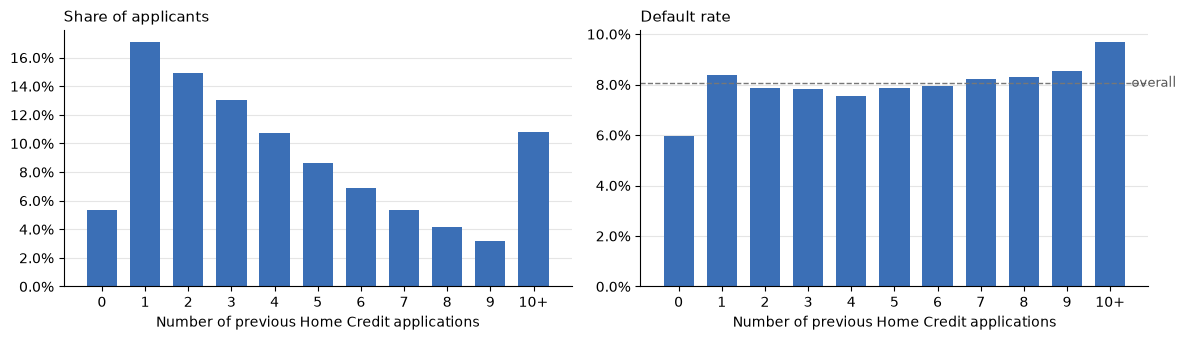

In [2]:
app = load("application_train")
assert app["SK_ID_CURR"].is_unique
n_prev = load("previous_application", usecols=["SK_ID_CURR"])["SK_ID_CURR"].value_counts()
app["N_PREV_APPS"] = app["SK_ID_CURR"].map(n_prev).fillna(0).astype("int16")
app["PREV_BUCKET"] = app["N_PREV_APPS"].clip(upper=10).astype("int8")   # 10 means "10 or more"
print(f"Applicants: {len(app):,} | default rate (TARGET=1): {app['TARGET'].mean():.2%}")

explore = (app.groupby("PREV_BUCKET")
              .agg(applicants=("SK_ID_CURR", "size"), default_rate=("TARGET", "mean"))
              .assign(share=lambda d: d["applicants"] / len(app)))
explore.index = [str(i) if i < 10 else "10+" for i in explore.index]
explore.index.name = "previous applications"
display(explore.style.format({"applicants": "{:,}", "default_rate": "{:.2%}", "share": "{:.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, col, title, fmt in [(axes[0], "share", "Share of applicants", "{:.0%}"),
                            (axes[1], "default_rate", "Default rate", "{:.1%}")]:
    ax.bar(explore.index, explore[col], color="#3B6FB6", width=0.7)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Number of previous Home Credit applications")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt.format(v)))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
axes[1].axhline(app["TARGET"].mean(), color="#777777", linestyle="--", linewidth=1)
axes[1].text(10.4, app["TARGET"].mean(), " overall", va="center", fontsize=9, color="#555555")
plt.tight_layout()
plt.show()

## Part 3 — Sample + filter all tables
**Step 1, sample applicants.** Pick 100,000 `SK_ID_CURR` from `application_train`, stratified on
TARGET × previous-application bucket.

**Step 2, filter every other table to those applicants** (this is what "apply the filter to all datasets" means):
* `bureau`, `previous_application`, `installments_payments`, `POS_CASH_balance`, `credit_card_balance`: keep rows
  whose `SK_ID_CURR` is in the sample.
* `bureau_balance` has no `SK_ID_CURR`, so keep rows whose `SK_ID_BUREAU` survived the bureau filter.

Sampling *applicants* rather than *rows* keeps each sampled applicant's history complete. Sampling 30% of each
table independently would leave applicants with half their repayment history missing.

In [3]:
# Step 1: stratified sample of applicants
strata = app["TARGET"].astype(str) + "_" + app["PREV_BUCKET"].astype(str)
sample_ids, _ = train_test_split(app["SK_ID_CURR"], train_size=SAMPLE_N, stratify=strata, random_state=SEED)
in_sample = app["SK_ID_CURR"].isin(sample_ids)

# Validate: the subset should match the full data, including on variables we did NOT stratify on.
# KS statistic = largest gap between the two distributions (< 0.01 means no practical difference).
app["N_BUREAU_RECORDS"] = app["SK_ID_CURR"].map(load("bureau", usecols=["SK_ID_CURR"])["SK_ID_CURR"].value_counts()).fillna(0)
rows = []
for col in ["TARGET", "N_PREV_APPS", "N_BUREAU_RECORDS", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
            "EXT_SOURCE_2", "EXT_SOURCE_3", "DAYS_BIRTH"]:
    full_v, sub_v = app[col].dropna(), app.loc[in_sample, col].dropna()
    rows.append({"variable": col, "full_data_mean": full_v.mean(), "subset_mean": sub_v.mean(),
                 "KS_stat": ks_2samp(full_v, sub_v).statistic})
sample_check = pd.DataFrame(rows).set_index("variable")
display(sample_check.style.format({"full_data_mean": "{:,.4f}", "subset_mean": "{:,.4f}", "KS_stat": "{:.4f}"}))
assert sample_check["KS_stat"].max() < 0.02, "subset differs from the full population"

app = app.loc[in_sample].drop(columns=["N_BUREAU_RECORDS"]).reset_index(drop=True)
SAMPLE = set(app["SK_ID_CURR"])
print(f"Sampled {len(app):,} applicants | default rate {app['TARGET'].mean():.3%}")

,full_data_mean,subset_mean,KS_stat
variable,,,
TARGET,0.0807,0.0807,0.0000
N_PREV_APPS,4.5972,4.5899,0.0008
N_BUREAU_RECORDS,4.7651,4.7613,0.0021
AMT_INCOME_TOTAL,"168,797.9219","168,358.2500",0.0026
AMT_CREDIT,"599,026.0000","599,296.0625",0.0021
AMT_ANNUITY,"27,108.5742","27,047.8359",0.0021
EXT_SOURCE_2,0.5144,0.5143,0.0015
EXT_SOURCE_3,0.5109,0.5100,0.0033
DAYS_BIRTH,"-16,036.9951","-16,039.7467",0.0020


Sampled 100,000 applicants | default rate 8.073%


In [4]:
# Step 2: filter every table to the sampled applicants
tables = {"application": app}
filter_log = [{"table": "application_train", "rows_before": len(in_sample), "rows_after": len(app)}]

for file in ["bureau", "previous_application", "installments_payments", "POS_CASH_balance", "credit_card_balance"]:
    df = load(file)
    kept = df[df["SK_ID_CURR"].isin(SAMPLE)].reset_index(drop=True)
    filter_log.append({"table": file, "rows_before": len(df), "rows_after": len(kept)})
    tables[TABLES[file]] = kept
    del df; gc.collect()

bb = load("bureau_balance")                               # no SK_ID_CURR: filter through the kept bureau loans
kept_bureau = tables["bureau"][["SK_ID_BUREAU", "SK_ID_CURR"]]
bb_kept = bb.merge(kept_bureau, on="SK_ID_BUREAU", how="inner")   # also attaches SK_ID_CURR for convenience
filter_log.append({"table": "bureau_balance", "rows_before": len(bb), "rows_after": len(bb_kept)})
tables["bureau_balance"] = bb_kept
del bb; gc.collect()

filter_log = pd.DataFrame(filter_log).set_index("table")
filter_log["kept"] = filter_log["rows_after"] / filter_log["rows_before"]
display(filter_log.style.format({"rows_before": "{:,}", "rows_after": "{:,}", "kept": "{:.1%}"}))

# Every remaining row must belong to a sampled applicant
for name, df in tables.items():
    assert df["SK_ID_CURR"].isin(SAMPLE).all(), name
print("All tables contain only sampled applicants.")

,rows_before,rows_after,kept
table,,,
application_train,"307,511","100,000",32.5%
bureau,"1,716,428","476,130",27.7%
previous_application,"1,670,214","458,993",27.5%
installments_payments,"13,605,401","3,776,583",27.8%
POS_CASH_balance,"10,001,358","2,773,426",27.7%
credit_card_balance,"3,840,312","1,062,183",27.7%
bureau_balance,"27,299,925","4,812,174",17.6%


All tables contain only sampled applicants.


## Part 4 — Train / validation / test split
The 100k applicants are split **once**, 70/15/15, stratified the same way. **All experiments must use this split**:
* train: fit models, and fit anything learned from data (imputation, scaling, thresholds)
* val: tune hyper-parameters and choose the decision threshold
* test: report final results only (Exp3's investigated applicants also come from here)

`is_dev` marks a stratified 20% of each split for quick trial runs. Final results use the whole split.

In [5]:
strata = app["TARGET"].astype(str) + "_" + app["PREV_BUCKET"].astype(str)
id_trval, id_test = train_test_split(app["SK_ID_CURR"], test_size=0.15, stratify=strata, random_state=SEED)
trval = app["SK_ID_CURR"].isin(id_trval)
id_train, id_val = train_test_split(app.loc[trval, "SK_ID_CURR"], test_size=0.15 / 0.85,
                                    stratify=strata[trval], random_state=SEED)

splits = app[["SK_ID_CURR", "TARGET", "N_PREV_APPS", "PREV_BUCKET"]].copy()
splits["split"] = np.select([splits["SK_ID_CURR"].isin(id_train), splits["SK_ID_CURR"].isin(id_val)],
                            ["train", "val"], default="test")
splits["is_dev"] = False
for s in ["train", "val", "test"]:
    part = splits[splits["split"] == s]
    dev_ids, _ = train_test_split(part["SK_ID_CURR"], train_size=DEV_FRAC, stratify=strata[part.index],
                                  random_state=SEED)
    splits.loc[splits["SK_ID_CURR"].isin(dev_ids), "is_dev"] = True
splits = splits.sort_values("SK_ID_CURR").reset_index(drop=True)
splits.to_csv(CLEAN / "splits.csv", index=False)

summary = splits.groupby("split").agg(applicants=("SK_ID_CURR", "size"), default_rate=("TARGET", "mean"),
                                      dev_applicants=("is_dev", "sum"))
display(summary.style.format({"applicants": "{:,}", "dev_applicants": "{:,}", "default_rate": "{:.3%}"}))
gap = (summary["default_rate"] - splits["TARGET"].mean()).abs().max()
assert gap < 0.002, "default rate differs across splits"
print(f"Split is balanced: default rates differ by at most {gap:.4%}")

,applicants,default_rate,dev_applicants
split,,,
test,"15,000",8.073%,"3,000"
train,"69,999",8.072%,"13,999"
val,"15,001",8.079%,"3,000"


Split is balanced: default rates differ by at most 0.0065%


## Part 5 — Clean each table
Cleaning only fixes **data errors** with fixed rules. Nothing is learned from the data, so cleaning cannot leak
information from val/test into training. Missing values are **left as NaN**; how to fill them is a modelling choice
each experiment makes using train data. Every rule and the number of rows it touched is recorded in
`cleaning_report.csv`.

In [6]:
report = []


def log(table, rule, n):
    report.append({"table": table, "rule": rule, "rows_affected": int(n)})


def to_missing(df, table, col, mask, rule):
    """Set df.loc[mask, col] to NaN (casting int columns to float first) and log it."""
    if pd.api.types.is_integer_dtype(df[col]):
        df[col] = df[col].astype("float32")
    log(table, f"{col}: {rule} -> NaN", mask.sum())
    df.loc[mask, col] = np.nan


def drop_categories(df, table, col, values):
    """Placeholder categories such as 'XNA' (not available) / 'XAP' (not applicable) -> NaN."""
    n = df[col].isin(values).sum()
    if n:
        df[col] = df[col].cat.remove_categories([v for v in values if v in df[col].cat.categories])
    log(table, f"{col}: {values} -> NaN", n)

### 5.1 application
| Problem | Fix |
|---|---|
| `DAYS_EMPLOYED = 365243` (placeholder, mostly pensioners) | NaN + new flag `DAYS_EMPLOYED_ANOM` |
| `CODE_GENDER = 'XNA'`, `NAME_FAMILY_STATUS = 'Unknown'`, `ORGANIZATION_TYPE = 'XNA'` | NaN |
| Income above 10 million (e.g. one applicant reports 117M) | NaN + flag `INCOME_OUTLIER` |
| Any `DAYS_*` > 0 (dates are counted backwards from the application, so must be ≤ 0) | NaN |

In [7]:
t = "application"
a = tables[t]
a["DAYS_EMPLOYED_ANOM"] = (a["DAYS_EMPLOYED"] == DAYS_SENTINEL).astype("int8")
to_missing(a, t, "DAYS_EMPLOYED", a["DAYS_EMPLOYED"] == DAYS_SENTINEL, "placeholder 365243")
drop_categories(a, t, "CODE_GENDER", ["XNA"])
drop_categories(a, t, "NAME_FAMILY_STATUS", ["Unknown"])
drop_categories(a, t, "ORGANIZATION_TYPE", ["XNA"])
a["INCOME_OUTLIER"] = (a["AMT_INCOME_TOTAL"] > 1e7).astype("int8")
to_missing(a, t, "AMT_INCOME_TOTAL", a["AMT_INCOME_TOTAL"] > 1e7, "> 10 million")
for c in [c for c in a.columns if c.startswith("DAYS_") and c != "DAYS_EMPLOYED_ANOM"]:
    if (a[c] > 0).any():
        to_missing(a, t, c, a[c] > 0, "positive (date after application)")
a = a.drop(columns=["N_PREV_APPS", "PREV_BUCKET"])   # helper columns from sampling (kept in splits.csv)
tables[t] = a

### 5.2 bureau and bureau_balance (loans at other lenders)
| Problem | Fix |
|---|---|
| `DAYS_CREDIT`, `DAYS_ENDDATE_FACT`, `DAYS_CREDIT_UPDATE` > 0, or any date more than 100 years ago | NaN |
| Negative debt (overpayment) | 0 |
| Negative credit limit | NaN |
| `bureau_balance.STATUS` is text: `0` on time, `1`–`5` increasingly late, `C` closed, `X` unknown | add numeric `STATUS_DPD` (0–5, NaN for C/X) and flags `IS_CLOSED`, `IS_UNKNOWN` |

`DAYS_CREDIT_ENDDATE` may legitimately be positive (a loan ending in the future).

In [8]:
t = "bureau"
b = tables[t]
for c in ["DAYS_CREDIT", "DAYS_ENDDATE_FACT", "DAYS_CREDIT_UPDATE"]:
    to_missing(b, t, c, (b[c] > 0) | (b[c] < -36500), "positive or > 100 years ago")
to_missing(b, t, "DAYS_CREDIT_ENDDATE", b["DAYS_CREDIT_ENDDATE"] < -36500, "> 100 years ago")
log(t, "AMT_CREDIT_SUM_DEBT: negative -> 0", (b["AMT_CREDIT_SUM_DEBT"] < 0).sum())
b["AMT_CREDIT_SUM_DEBT"] = b["AMT_CREDIT_SUM_DEBT"].clip(lower=0)
to_missing(b, t, "AMT_CREDIT_SUM_LIMIT", b["AMT_CREDIT_SUM_LIMIT"] < 0, "negative")
assert b["SK_ID_BUREAU"].is_unique

t = "bureau_balance"
bb = tables[t]
status = bb["STATUS"].astype(str)
bb["STATUS_DPD"] = pd.to_numeric(status.where(status.str.isdigit()), errors="coerce").astype("float32")
bb["IS_CLOSED"] = (status == "C").astype("int8")
bb["IS_UNKNOWN"] = (status == "X").astype("int8")
log(t, "STATUS C/X -> STATUS_DPD NaN (flags added)", status.isin(["C", "X"]).sum())
del status

### 5.3 previous_application (past Home Credit applications)
| Problem | Fix |
|---|---|
| `DAYS_FIRST_DRAWING / FIRST_DUE / LAST_DUE_1ST_VERSION / LAST_DUE / TERMINATION = 365243` | NaN |
| `XNA` / `XAP` placeholder categories in any text column | NaN |
| `SELLERPLACE_AREA = -1` | NaN |
| Negative down payment | 0 |
| `FLAG_LAST_APPL_PER_CONTRACT = 'N'`: the same contract submitted twice | **kept**, flagged `IS_DUPLICATE_SUBMISSION` |

In [9]:
t = "previous_application"
p = tables[t]
for c in ["DAYS_FIRST_DRAWING", "DAYS_FIRST_DUE", "DAYS_LAST_DUE_1ST_VERSION", "DAYS_LAST_DUE", "DAYS_TERMINATION"]:
    to_missing(p, t, c, p[c] == DAYS_SENTINEL, "placeholder 365243")
for c in [c for c in p.columns if isinstance(p[c].dtype, pd.CategoricalDtype)]:
    if p[c].isin(["XNA", "XAP"]).any():
        drop_categories(p, t, c, ["XNA", "XAP"])
to_missing(p, t, "SELLERPLACE_AREA", p["SELLERPLACE_AREA"] == -1, "-1 placeholder")
for c in ["RATE_DOWN_PAYMENT", "AMT_DOWN_PAYMENT"]:
    log(t, f"{c}: negative -> 0", (p[c] < 0).sum())
    p[c] = p[c].clip(lower=0)
p["IS_DUPLICATE_SUBMISSION"] = (p["FLAG_LAST_APPL_PER_CONTRACT"].astype(str) == "N").astype("int8")
log(t, "duplicate submissions flagged (kept)", p["IS_DUPLICATE_SUBMISSION"].sum())
assert p["SK_ID_PREV"].is_unique

### 5.4 installments_payments, POS_CASH_balance, credit_card_balance
| Table | Problem | Fix |
|---|---|---|
| installments | exact duplicate rows | dropped |
| installments | one instalment paid in **several rows** (split payments, ~5% of instalments) | **merged** into one row per instalment (see below) |
| installments | no payment recorded (`AMT_PAYMENT` missing) | **kept as NaN**: a missed payment is real information |
| POS / credit card | `NAME_CONTRACT_STATUS = 'XNA'` | NaN |
| credit card | negative drawing amounts | NaN |

**Why merge split payments?** An instalment of 14,614 paid as 5,614 + 9,000 appears as two rows. Read row by row,
the first looks like a large underpayment. Unmerged, about 9.5% of rows look underpaid; after merging, only ~0.04% of
instalments truly are. Merging once here means every experiment uses the same, correct repayment records.

One row per instalment (`SK_ID_PREV, NUM_INSTALMENT_VERSION, NUM_INSTALMENT_NUMBER`):

| Column | Meaning after merging |
|---|---|
| `DAYS_INSTALMENT`, `AMT_INSTALMENT` | due date and amount due (identical across the split rows) |
| `AMT_PAYMENT` | **total** paid across all parts (NaN if nothing was recorded) |
| `DAYS_ENTRY_PAYMENT` | date of the **last** part, i.e. when the instalment was fully paid (use this for lateness) |
| `DAYS_FIRST_PAYMENT` | date of the first part |
| `N_PAYMENTS` | number of separate payments (1 = paid in one go), so the "paid in parts" detail is not lost |

In [10]:
t = "installments"
i = tables[t]
n = len(i)
i = i.drop_duplicates().reset_index(drop=True)
log(t, "exact duplicate rows dropped", n - len(i))

keys = ["SK_ID_CURR", "SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"]
n_due = i.groupby(keys, observed=True)["AMT_INSTALMENT"].nunique()
log(t, "instalments whose split rows disagree on amount due (max kept)", (n_due > 1).sum())
merged = (i.groupby(keys, observed=True, sort=False)
           .agg(DAYS_INSTALMENT=("DAYS_INSTALMENT", "min"),
                AMT_INSTALMENT=("AMT_INSTALMENT", "max"),
                AMT_PAYMENT=("AMT_PAYMENT", lambda s: s.sum(min_count=1)),   # NaN if no payment recorded
                DAYS_FIRST_PAYMENT=("DAYS_ENTRY_PAYMENT", "min"),
                DAYS_ENTRY_PAYMENT=("DAYS_ENTRY_PAYMENT", "max"),
                N_PAYMENTS=("AMT_PAYMENT", "count"))
           .reset_index())
merged["N_PAYMENTS"] = merged["N_PAYMENTS"].astype("int16")
merged = merged.sort_values(["SK_ID_CURR", "SK_ID_PREV", "DAYS_INSTALMENT"]).reset_index(drop=True)
log(t, "split payments merged: rows removed (now one row per instalment)", len(i) - len(merged))
log(t, "instalments paid in more than one part (N_PAYMENTS > 1)", (merged["N_PAYMENTS"] > 1).sum())
log(t, "instalments with no payment recorded (AMT_PAYMENT kept NaN)", merged["AMT_PAYMENT"].isna().sum())
assert not merged.duplicated(keys).any()
tables[t] = merged
del n_due   # raw rows `i` are freed with the other tables in 5.5

t = "pos_cash"
drop_categories(tables[t], t, "NAME_CONTRACT_STATUS", ["XNA"])

t = "credit_card"
c_ = tables[t]
for c in ["AMT_DRAWINGS_ATM_CURRENT", "AMT_DRAWINGS_CURRENT", "AMT_DRAWINGS_OTHER_CURRENT", "AMT_DRAWINGS_POS_CURRENT"]:
    to_missing(c_, t, c, c_[c] < 0, "negative")
drop_categories(c_, t, "NAME_CONTRACT_STATUS", ["XNA"])

### 5.5 Save the cleaned tables + cleaning report

In [11]:
saved = []
for name, df in tables.items():
    df.to_parquet(CLEAN / f"{name}.parquet", index=False)
    saved.append({"file": f"{name}.parquet", "rows": len(df), "columns": df.shape[1],
                  "applicants": df["SK_ID_CURR"].nunique(),
                  "size_MB": (CLEAN / f"{name}.parquet").stat().st_size / 1e6})
report = pd.DataFrame(report)
report.to_csv(CLEAN / "cleaning_report.csv", index=False)
display(report.style.format({"rows_affected": "{:,}"}))
display(pd.DataFrame(saved).set_index("file").style.format({"rows": "{:,}", "applicants": "{:,}", "size_MB": "{:.1f}"}))

coverage = pd.DataFrame({
    name: [splits["SK_ID_CURR"].isin(tables[name]["SK_ID_CURR"]).mean(),
           splits.loc[splits["SK_ID_CURR"].isin(tables[name]["SK_ID_CURR"]), "TARGET"].mean(),
           splits.loc[~splits["SK_ID_CURR"].isin(tables[name]["SK_ID_CURR"]), "TARGET"].mean()]
    for name in ["bureau", "previous_application", "installments", "pos_cash", "credit_card"]
}, index=["applicants_with_records", "default_rate_with", "default_rate_without"]).T
print("Coverage: how many applicants have each type of history (missing history is itself informative)")
display(coverage.style.format("{:.2%}"))
del tables, a, b, bb, p, i, c_; gc.collect()
print(f"Parts 1-5 done in {(time.time() - T0) / 60:.1f} min")

,table,rule,rows_affected
0,application,DAYS_EMPLOYED: placeholder 365243 -> NaN,"18,242"
1,application,CODE_GENDER: ['XNA'] -> NaN,1
2,application,NAME_FAMILY_STATUS: ['Unknown'] -> NaN,1
3,application,ORGANIZATION_TYPE: ['XNA'] -> NaN,"18,242"
4,application,AMT_INCOME_TOTAL: > 10 million -> NaN,1
5,bureau,DAYS_CREDIT: positive or > 100 years ago -> NaN,0
6,bureau,DAYS_ENDDATE_FACT: positive or > 100 years ago -> NaN,1
7,bureau,DAYS_CREDIT_UPDATE: positive or > 100 years ago -> NaN,36
8,bureau,DAYS_CREDIT_ENDDATE: > 100 years ago -> NaN,40
9,bureau,AMT_CREDIT_SUM_DEBT: negative -> 0,"2,769"


,rows,columns,applicants,size_MB
file,,,,
application.parquet,"100,000",124,"100,000",7.4
bureau.parquet,"476,130",17,"85,614",9.8
previous_application.parquet,"458,993",38,"94,649",15.3
installments.parquet,"3,593,241",10,"94,876",37.0
pos_cash.parquet,"2,773,426",8,"94,164",23.5
credit_card.parquet,"1,062,183",23,"28,368",27.4
bureau_balance.parquet,"4,812,174",7,"29,922",5.0


Coverage: how many applicants have each type of history (missing history is itself informative)


,applicants_with_records,default_rate_with,default_rate_without
bureau,85.61%,7.74%,10.04%
previous_application,94.65%,8.19%,5.96%
installments,94.88%,8.19%,5.89%
pos_cash,94.16%,8.16%,6.68%
credit_card,28.37%,8.83%,7.77%


Parts 1-5 done in 1.6 min


## Part 6 — Evaluation framework (one file per experiment)
Each experiment gets its own folder with **an evaluation notebook** (`evaluate_expN.ipynb`: fill in your models,
Run All, get formatted tables) and **the `.py` file behind it**, which also runs from the terminal. The first section of each file (common metrics) is identical, so all experiments compute
ROC-AUC, PR-AUC, precision/recall/F1 etc. in exactly the same way on the same test applicants.

| Folder | File | What it evaluates | Run it with |
|---|---|---|---|
| `outputs/exp1/` | `eval_exp1.py` | application-only vs multi-source models (ablation) | `python outputs/exp1/eval_exp1.py app.csv all.csv` |
| `outputs/exp2/` | `eval_exp2.py` | aggregated vs sequence models, overall **and per history segment** (RQ2.2) | `python outputs/exp2/eval_exp2.py agg.csv seq.csv` |
| `outputs/exp3/` | `eval_exp3.py` | agent faithfulness, completeness, consistency, discrimination | `python outputs/exp3/eval_exp3.py agent_runs.jsonl --flag-map flag_to_fields.json` |

**Input for Exp1/Exp2:** one CSV per model with columns `SK_ID_CURR, score` for all val and test applicants
(higher score = riskier). The threshold for precision/recall/F1 is chosen on val, and metrics are reported on test.

**Reference files** (built in 6.4):
* `exp2/history_segments.parquet`: default history groups for RQ2.2. The Exp2 owner may replace them with
  their own groups (`--segments my_groups.csv`).
* `exp3/red_flags.parquet` + `red_flag_rules.json`: the rule-based answer key for completeness.

In [12]:
%%writefile outputs/exp1/eval_exp1.py
"""Exp1 evaluation: application-only vs multi-source models (ablation), all on the shared test set.

Usage
-----
Save one predictions CSV per model with columns SK_ID_CURR, score (val + test applicants; higher = riskier):

    python outputs/exp1/eval_exp1.py app_only.csv app_bureau.csv app_prev.csv app_repay.csv all_sources.csv \
        --labels App +Bureau +Prev +Repayment All

The first file is the baseline. Prints test metrics for every model and paired significance tests vs the baseline,
and saves exp1_metrics.csv and exp1_comparisons.csv next to this file.
In Python:  import eval_exp1 as ev;  ev.evaluate(y_test, p_test, y_val=y_val, s_val=p_val)
"""
# ============================================================================================
# COMMON METRICS (identical in eval_exp1.py, eval_exp2.py and eval_exp3.py, so each file runs on its own)
# ============================================================================================
import argparse
import json
import math
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)

HERE = Path(__file__).resolve().parent
CLEAN_DIR = HERE.parent / "clean_data"
SHOW = ["roc_auc", "pr_auc", "precision", "recall", "f1", "precision@top10%", "recall@top10%"]


def load_splits(clean_dir=CLEAN_DIR):
    """The shared split: SK_ID_CURR, TARGET, N_PREV_APPS, PREV_BUCKET, split (train/val/test), is_dev."""
    return pd.read_csv(Path(clean_dir) / "splits.csv")


def attach_split(df, id_col="SK_ID_CURR", clean_dir=CLEAN_DIR):
    """Add TARGET, split and is_dev columns from the shared splits.csv."""
    s = load_splits(clean_dir)[["SK_ID_CURR", "TARGET", "split", "is_dev"]]
    df = df.drop(columns=[c for c in ["TARGET", "split", "is_dev"] if c in df.columns])
    return df.merge(s, left_on=id_col, right_on="SK_ID_CURR", how="left")


def best_f1_threshold(y_val, s_val):
    """Decision threshold that maximises F1 on VALIDATION data (never choose it on test)."""
    p, r, t = precision_recall_curve(y_val, s_val)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.nanargmax(f1[:-1])])


def _top_k(y, s, frac):
    k = max(1, int(round(len(s) * frac)))
    hits = y[np.argsort(-s)[:k]].sum()
    return hits / k, hits / max(1, y.sum())


def _metrics(y, s, thr):
    yhat = (s >= thr).astype(int)
    out = {"roc_auc": roc_auc_score(y, s), "pr_auc": average_precision_score(y, s),
           "precision": precision_score(y, yhat, zero_division=0), "recall": recall_score(y, yhat),
           "f1": f1_score(y, yhat)}
    for frac in (0.05, 0.10):
        out[f"precision@top{int(frac * 100)}%"], out[f"recall@top{int(frac * 100)}%"] = _top_k(y, s, frac)
    return out


def evaluate(y_test, s_test, y_val=None, s_val=None, threshold=None, n_boot=1000, seed=42):
    """Test metrics with bootstrap 95% CIs: ROC-AUC, PR-AUC, precision/recall/F1 at the threshold, and
    precision/recall among the riskiest 5% and 10%. Threshold = max-F1 on validation, or a fixed `threshold`."""
    if threshold is None:
        if y_val is None:
            raise ValueError("give validation labels/scores (y_val, s_val) or a fixed threshold")
        threshold = best_f1_threshold(y_val, s_val)
    y, s = np.asarray(y_test).astype(int), np.asarray(s_test, dtype=float)
    point = _metrics(y, s, threshold)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            boots.append(_metrics(y[i], s[i], threshold))
    boots = pd.DataFrame(boots)
    res = pd.DataFrame({"value": point, "ci_low": boots.quantile(0.025), "ci_high": boots.quantile(0.975)})
    res.attrs["threshold"] = threshold
    return res


def delong_test(y, s_a, s_b):
    """DeLong test for the difference between two ROC-AUCs measured on the same rows."""
    y = np.asarray(y).astype(int)
    preds = np.vstack([s_a, s_b]).astype(float)
    pos, neg = preds[:, y == 1], preds[:, y == 0]
    m, n = pos.shape[1], neg.shape[1]
    tz = stats.rankdata(np.concatenate([pos, neg], axis=1), axis=1)
    tx, ty = stats.rankdata(pos, axis=1), stats.rankdata(neg, axis=1)
    aucs = (tz[:, :m].sum(axis=1) / m - (m + 1) / 2) / n
    cov = np.cov((tz[:, :m] - tx) / n) / m + np.cov(1 - (tz[:, m:] - ty) / m) / n
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    z = (aucs[0] - aucs[1]) / math.sqrt(var) if var > 0 else 0.0
    return {"auc_a": float(aucs[0]), "auc_b": float(aucs[1]), "delta": float(aucs[0] - aucs[1]),
            "z": float(z), "p_value": float(2 * stats.norm.sf(abs(z)))}


def compare_models(y, s_a, s_b, metric="pr_auc", n_boot=1000, seed=42):
    """Is model A better than model B on the SAME rows? Paired bootstrap of metric(A) - metric(B), plus DeLong."""
    f = {"roc_auc": roc_auc_score, "pr_auc": average_precision_score}[metric]
    y, s_a, s_b = np.asarray(y).astype(int), np.asarray(s_a, float), np.asarray(s_b, float)
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            d.append(f(y[i], s_a[i]) - f(y[i], s_b[i]))
    d = np.array(d)
    return {"metric": metric, "delta": float(f(y, s_a) - f(y, s_b)), "ci_low": float(np.quantile(d, 0.025)),
            "ci_high": float(np.quantile(d, 0.975)),
            "p_bootstrap": float(min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))),
            "delong_roc_auc": delong_test(y, s_a, s_b)}


def load_predictions(pred, clean_dir=CLEAN_DIR):
    """Predictions as a DataFrame or a CSV path, with columns SK_ID_CURR, score (higher = riskier).
    Returns them with TARGET and split attached."""
    name = "predictions DataFrame" if isinstance(pred, pd.DataFrame) else str(pred)
    p = pred if isinstance(pred, pd.DataFrame) else pd.read_csv(pred)
    missing = {"SK_ID_CURR", "score"} - set(p.columns)
    if missing:
        raise ValueError(f"{name}: missing column(s) {sorted(missing)}; expected SK_ID_CURR, score")
    df = attach_split(p[["SK_ID_CURR", "score"]].drop_duplicates("SK_ID_CURR"), clean_dir=clean_dir)
    if df["split"].isna().any():
        raise ValueError(f"{name}: {df['split'].isna().sum()} SK_ID_CURR are not in the shared sample (splits.csv)")
    return df


def compare_prediction_files(paths, labels=None, n_boot=1000, clean_dir=CLEAN_DIR):
    """Evaluate several models on the SAME test applicants. Each entry (DataFrame or CSV path) needs val rows
    (to pick the threshold) and every test applicant. The first entry is the baseline the others are compared with.
    Returns (metrics table, comparison table, per-model predictions)."""
    labels = labels or [f"model_{k + 1}" if isinstance(p, pd.DataFrame) else Path(p).stem for k, p in enumerate(paths)]
    test_ids = set(load_splits(clean_dir).query("split == 'test'")["SK_ID_CURR"])
    preds, rows = {}, []
    for lab, path in zip(labels, paths):
        df = load_predictions(path, clean_dir)
        va, te = df[df.split == "val"], df[df.split == "test"].sort_values("SK_ID_CURR")
        if va.empty:
            raise ValueError(f"{lab}: no validation rows; they are needed to choose the decision threshold")
        if set(te["SK_ID_CURR"]) != test_ids:
            raise ValueError(f"{lab}: must score all {len(test_ids):,} test applicants (found {len(te):,})")
        res = evaluate(te.TARGET, te.score, y_val=va.TARGET, s_val=va.score, n_boot=n_boot)
        preds[lab] = {"val": va, "test": te, "threshold": res.attrs["threshold"]}
        row = {"model": lab, "threshold": res.attrs["threshold"]}
        for m, r in res.iterrows():
            row[m], row[f"{m}_ci_low"], row[f"{m}_ci_high"] = r["value"], r["ci_low"], r["ci_high"]
        rows.append(row)
    table = pd.DataFrame(rows).set_index("model")
    comps = []
    base = labels[0]
    for lab in labels[1:]:
        y = preds[base]["test"]["TARGET"].to_numpy()
        for metric in ("roc_auc", "pr_auc"):
            c = compare_models(y, preds[lab]["test"]["score"], preds[base]["test"]["score"], metric, n_boot)
            comps.append({"model": lab, "vs_baseline": base, "metric": metric, "delta": c["delta"],
                          "ci_low": c["ci_low"], "ci_high": c["ci_high"], "p_bootstrap": c["p_bootstrap"],
                          "p_delong": c["delong_roc_auc"]["p_value"] if metric == "roc_auc" else np.nan})
    return table, pd.DataFrame(comps), preds


def pretty_metrics(table, metrics=SHOW):
    """Readable metrics table: 'value (95% CI low-high)' per metric, one row per model."""
    out = pd.DataFrame({"threshold": table["threshold"].round(3)}, index=table.index)
    for m in metrics:
        out[m] = [f"{v:.3f} ({lo:.3f}-{hi:.3f})"
                  for v, lo, hi in zip(table[m], table[f"{m}_ci_low"], table[f"{m}_ci_high"])]
    return out


def pretty_comparisons(comps):
    """Readable comparison table with a plain-language verdict (95% CI of the difference excludes 0)."""
    if comps.empty:
        return comps
    c = comps.copy()
    c["difference (95% CI)"] = [f"{d:+.4f} ({lo:+.4f} to {hi:+.4f})" for d, lo, hi in zip(c.delta, c.ci_low, c.ci_high)]
    c["p_value"] = [f"{pd_:.2g}" if metric == "roc_auc" else f"{pb:.2g}"
                    for pd_, pb, metric in zip(c.p_delong, c.p_bootstrap, c.metric)]
    c["verdict"] = np.where(c.ci_low > 0, "significantly better", np.where(c.ci_high < 0, "significantly worse",
                                                                           "no significant difference"))
    return c[["model", "vs_baseline", "metric", "difference (95% CI)", "p_value", "verdict"]]


def _print_model_table(table, comps):
    pd.set_option("display.width", 200)
    print("\nTest-set metrics, value (95% CI); threshold chosen on validation")
    print(pretty_metrics(table).to_string())
    if len(comps):
        print("\nPaired comparison vs baseline (same test applicants)")
        print(pretty_comparisons(comps).to_string(index=False))


def _predictions_cli(description, epilog):
    ap = argparse.ArgumentParser(description=description, epilog=epilog,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("predictions", nargs="+",
                    help="CSV file(s) with columns SK_ID_CURR, score for val + test applicants. First file = baseline.")
    ap.add_argument("--labels", nargs="+", help="model names (default: file names)")
    ap.add_argument("--n-boot", type=int, default=1000, help="bootstrap resamples for CIs (default 1000)")
    return ap


# ============================================================================================
# EXP1 COMMAND LINE
# ============================================================================================
def main(argv=None):
    ap = _predictions_cli("Exp1: compare application-only vs multi-source models on the shared test set.",
                          "Example:\n  python eval_exp1.py app_only.csv all_sources.csv --labels App All")
    ap.add_argument("--out", default=str(HERE / "exp1"), help="output file prefix (default outputs/exp1/exp1)")
    a = ap.parse_args(argv)
    table, comps, _ = compare_prediction_files(a.predictions, a.labels, a.n_boot)
    _print_model_table(table, comps)
    table.to_csv(f"{a.out}_metrics.csv")
    comps.to_csv(f"{a.out}_comparisons.csv", index=False)
    print(f"\nSaved {a.out}_metrics.csv and {a.out}_comparisons.csv")


if __name__ == "__main__":
    try:
        main()
    except (ValueError, FileNotFoundError) as e:
        sys.exit(f"Error: {e}")

Overwriting outputs/exp1/eval_exp1.py


In [13]:
%%writefile outputs/exp2/eval_exp2.py
"""Exp2 evaluation: aggregated vs temporal (sequence) models, overall and by history segment (RQ2.1 + RQ2.2).

Usage
-----
Save one predictions CSV per model with columns SK_ID_CURR, score (val + test applicants; higher = riskier):

    python outputs/exp2/eval_exp2.py aggregated_mlp.csv sequence_gru.csv --labels Aggregated Sequence

The first file is the baseline. Prints overall test metrics, paired significance tests vs the baseline, and the same
metrics for each history segment (default groups in history_segments.parquet). To use your own groups, pass
--segments my_groups.csv with columns SK_ID_CURR, segment. Saves exp2_metrics.csv, exp2_comparisons.csv and
exp2_by_segment.csv next to this file.
"""
# ============================================================================================
# COMMON METRICS (identical in eval_exp1.py, eval_exp2.py and eval_exp3.py, so each file runs on its own)
# ============================================================================================
import argparse
import json
import math
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)

HERE = Path(__file__).resolve().parent
CLEAN_DIR = HERE.parent / "clean_data"
SHOW = ["roc_auc", "pr_auc", "precision", "recall", "f1", "precision@top10%", "recall@top10%"]


def load_splits(clean_dir=CLEAN_DIR):
    """The shared split: SK_ID_CURR, TARGET, N_PREV_APPS, PREV_BUCKET, split (train/val/test), is_dev."""
    return pd.read_csv(Path(clean_dir) / "splits.csv")


def attach_split(df, id_col="SK_ID_CURR", clean_dir=CLEAN_DIR):
    """Add TARGET, split and is_dev columns from the shared splits.csv."""
    s = load_splits(clean_dir)[["SK_ID_CURR", "TARGET", "split", "is_dev"]]
    df = df.drop(columns=[c for c in ["TARGET", "split", "is_dev"] if c in df.columns])
    return df.merge(s, left_on=id_col, right_on="SK_ID_CURR", how="left")


def best_f1_threshold(y_val, s_val):
    """Decision threshold that maximises F1 on VALIDATION data (never choose it on test)."""
    p, r, t = precision_recall_curve(y_val, s_val)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.nanargmax(f1[:-1])])


def _top_k(y, s, frac):
    k = max(1, int(round(len(s) * frac)))
    hits = y[np.argsort(-s)[:k]].sum()
    return hits / k, hits / max(1, y.sum())


def _metrics(y, s, thr):
    yhat = (s >= thr).astype(int)
    out = {"roc_auc": roc_auc_score(y, s), "pr_auc": average_precision_score(y, s),
           "precision": precision_score(y, yhat, zero_division=0), "recall": recall_score(y, yhat),
           "f1": f1_score(y, yhat)}
    for frac in (0.05, 0.10):
        out[f"precision@top{int(frac * 100)}%"], out[f"recall@top{int(frac * 100)}%"] = _top_k(y, s, frac)
    return out


def evaluate(y_test, s_test, y_val=None, s_val=None, threshold=None, n_boot=1000, seed=42):
    """Test metrics with bootstrap 95% CIs: ROC-AUC, PR-AUC, precision/recall/F1 at the threshold, and
    precision/recall among the riskiest 5% and 10%. Threshold = max-F1 on validation, or a fixed `threshold`."""
    if threshold is None:
        if y_val is None:
            raise ValueError("give validation labels/scores (y_val, s_val) or a fixed threshold")
        threshold = best_f1_threshold(y_val, s_val)
    y, s = np.asarray(y_test).astype(int), np.asarray(s_test, dtype=float)
    point = _metrics(y, s, threshold)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            boots.append(_metrics(y[i], s[i], threshold))
    boots = pd.DataFrame(boots)
    res = pd.DataFrame({"value": point, "ci_low": boots.quantile(0.025), "ci_high": boots.quantile(0.975)})
    res.attrs["threshold"] = threshold
    return res


def delong_test(y, s_a, s_b):
    """DeLong test for the difference between two ROC-AUCs measured on the same rows."""
    y = np.asarray(y).astype(int)
    preds = np.vstack([s_a, s_b]).astype(float)
    pos, neg = preds[:, y == 1], preds[:, y == 0]
    m, n = pos.shape[1], neg.shape[1]
    tz = stats.rankdata(np.concatenate([pos, neg], axis=1), axis=1)
    tx, ty = stats.rankdata(pos, axis=1), stats.rankdata(neg, axis=1)
    aucs = (tz[:, :m].sum(axis=1) / m - (m + 1) / 2) / n
    cov = np.cov((tz[:, :m] - tx) / n) / m + np.cov(1 - (tz[:, m:] - ty) / m) / n
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    z = (aucs[0] - aucs[1]) / math.sqrt(var) if var > 0 else 0.0
    return {"auc_a": float(aucs[0]), "auc_b": float(aucs[1]), "delta": float(aucs[0] - aucs[1]),
            "z": float(z), "p_value": float(2 * stats.norm.sf(abs(z)))}


def compare_models(y, s_a, s_b, metric="pr_auc", n_boot=1000, seed=42):
    """Is model A better than model B on the SAME rows? Paired bootstrap of metric(A) - metric(B), plus DeLong."""
    f = {"roc_auc": roc_auc_score, "pr_auc": average_precision_score}[metric]
    y, s_a, s_b = np.asarray(y).astype(int), np.asarray(s_a, float), np.asarray(s_b, float)
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            d.append(f(y[i], s_a[i]) - f(y[i], s_b[i]))
    d = np.array(d)
    return {"metric": metric, "delta": float(f(y, s_a) - f(y, s_b)), "ci_low": float(np.quantile(d, 0.025)),
            "ci_high": float(np.quantile(d, 0.975)),
            "p_bootstrap": float(min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))),
            "delong_roc_auc": delong_test(y, s_a, s_b)}


def load_predictions(pred, clean_dir=CLEAN_DIR):
    """Predictions as a DataFrame or a CSV path, with columns SK_ID_CURR, score (higher = riskier).
    Returns them with TARGET and split attached."""
    name = "predictions DataFrame" if isinstance(pred, pd.DataFrame) else str(pred)
    p = pred if isinstance(pred, pd.DataFrame) else pd.read_csv(pred)
    missing = {"SK_ID_CURR", "score"} - set(p.columns)
    if missing:
        raise ValueError(f"{name}: missing column(s) {sorted(missing)}; expected SK_ID_CURR, score")
    df = attach_split(p[["SK_ID_CURR", "score"]].drop_duplicates("SK_ID_CURR"), clean_dir=clean_dir)
    if df["split"].isna().any():
        raise ValueError(f"{name}: {df['split'].isna().sum()} SK_ID_CURR are not in the shared sample (splits.csv)")
    return df


def compare_prediction_files(paths, labels=None, n_boot=1000, clean_dir=CLEAN_DIR):
    """Evaluate several models on the SAME test applicants. Each entry (DataFrame or CSV path) needs val rows
    (to pick the threshold) and every test applicant. The first entry is the baseline the others are compared with.
    Returns (metrics table, comparison table, per-model predictions)."""
    labels = labels or [f"model_{k + 1}" if isinstance(p, pd.DataFrame) else Path(p).stem for k, p in enumerate(paths)]
    test_ids = set(load_splits(clean_dir).query("split == 'test'")["SK_ID_CURR"])
    preds, rows = {}, []
    for lab, path in zip(labels, paths):
        df = load_predictions(path, clean_dir)
        va, te = df[df.split == "val"], df[df.split == "test"].sort_values("SK_ID_CURR")
        if va.empty:
            raise ValueError(f"{lab}: no validation rows; they are needed to choose the decision threshold")
        if set(te["SK_ID_CURR"]) != test_ids:
            raise ValueError(f"{lab}: must score all {len(test_ids):,} test applicants (found {len(te):,})")
        res = evaluate(te.TARGET, te.score, y_val=va.TARGET, s_val=va.score, n_boot=n_boot)
        preds[lab] = {"val": va, "test": te, "threshold": res.attrs["threshold"]}
        row = {"model": lab, "threshold": res.attrs["threshold"]}
        for m, r in res.iterrows():
            row[m], row[f"{m}_ci_low"], row[f"{m}_ci_high"] = r["value"], r["ci_low"], r["ci_high"]
        rows.append(row)
    table = pd.DataFrame(rows).set_index("model")
    comps = []
    base = labels[0]
    for lab in labels[1:]:
        y = preds[base]["test"]["TARGET"].to_numpy()
        for metric in ("roc_auc", "pr_auc"):
            c = compare_models(y, preds[lab]["test"]["score"], preds[base]["test"]["score"], metric, n_boot)
            comps.append({"model": lab, "vs_baseline": base, "metric": metric, "delta": c["delta"],
                          "ci_low": c["ci_low"], "ci_high": c["ci_high"], "p_bootstrap": c["p_bootstrap"],
                          "p_delong": c["delong_roc_auc"]["p_value"] if metric == "roc_auc" else np.nan})
    return table, pd.DataFrame(comps), preds


def pretty_metrics(table, metrics=SHOW):
    """Readable metrics table: 'value (95% CI low-high)' per metric, one row per model."""
    out = pd.DataFrame({"threshold": table["threshold"].round(3)}, index=table.index)
    for m in metrics:
        out[m] = [f"{v:.3f} ({lo:.3f}-{hi:.3f})"
                  for v, lo, hi in zip(table[m], table[f"{m}_ci_low"], table[f"{m}_ci_high"])]
    return out


def pretty_comparisons(comps):
    """Readable comparison table with a plain-language verdict (95% CI of the difference excludes 0)."""
    if comps.empty:
        return comps
    c = comps.copy()
    c["difference (95% CI)"] = [f"{d:+.4f} ({lo:+.4f} to {hi:+.4f})" for d, lo, hi in zip(c.delta, c.ci_low, c.ci_high)]
    c["p_value"] = [f"{pd_:.2g}" if metric == "roc_auc" else f"{pb:.2g}"
                    for pd_, pb, metric in zip(c.p_delong, c.p_bootstrap, c.metric)]
    c["verdict"] = np.where(c.ci_low > 0, "significantly better", np.where(c.ci_high < 0, "significantly worse",
                                                                           "no significant difference"))
    return c[["model", "vs_baseline", "metric", "difference (95% CI)", "p_value", "verdict"]]


def _print_model_table(table, comps):
    pd.set_option("display.width", 200)
    print("\nTest-set metrics, value (95% CI); threshold chosen on validation")
    print(pretty_metrics(table).to_string())
    if len(comps):
        print("\nPaired comparison vs baseline (same test applicants)")
        print(pretty_comparisons(comps).to_string(index=False))


def _predictions_cli(description, epilog):
    ap = argparse.ArgumentParser(description=description, epilog=epilog,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("predictions", nargs="+",
                    help="CSV file(s) with columns SK_ID_CURR, score for val + test applicants. First file = baseline.")
    ap.add_argument("--labels", nargs="+", help="model names (default: file names)")
    ap.add_argument("--n-boot", type=int, default=1000, help="bootstrap resamples for CIs (default 1000)")
    return ap


# ============================================================================================
# EXP2: HISTORY SEGMENTS (RQ2.2)
# ============================================================================================
SEGMENTS_FILE = HERE / "history_segments.parquet"


def history_segments(clean_dir=CLEAN_DIR):
    """Default RQ2.2 groups per applicant.
    HISTORY_SEGMENT: internal (Home Credit records) and/or external (credit bureau) history, or none.
    INTERNAL_RICHNESS: quartile of the number of internal records (cut-points from TRAIN applicants), or 'none'."""
    d = Path(clean_dir)
    sp = load_splits(d)
    ids = sp["SK_ID_CURR"]
    internal = sum(pd.read_parquet(d / f"{t}.parquet", columns=["SK_ID_CURR"])["SK_ID_CURR"].value_counts()
                   .reindex(ids, fill_value=0).to_numpy()
                   for t in ["previous_application", "installments", "pos_cash", "credit_card"])
    has_bureau = ids.isin(pd.read_parquet(d / "bureau.parquet", columns=["SK_ID_CURR"])["SK_ID_CURR"]).to_numpy()
    seg = pd.DataFrame({"SK_ID_CURR": ids, "split": sp["split"], "N_INTERNAL_RECORDS": internal,
                        "HAS_INTERNAL": internal > 0, "HAS_EXTERNAL": has_bureau})
    seg["HISTORY_SEGMENT"] = np.select(
        [seg.HAS_INTERNAL & seg.HAS_EXTERNAL, seg.HAS_INTERNAL, seg.HAS_EXTERNAL],
        ["internal+external", "internal_only", "external_only"], default="no_history")
    cuts = seg.loc[(seg.split == "train") & seg.HAS_INTERNAL, "N_INTERNAL_RECORDS"].quantile([.25, .5, .75]).to_numpy()
    q = np.searchsorted(cuts, seg["N_INTERNAL_RECORDS"], side="right") + 1
    seg["INTERNAL_RICHNESS"] = np.where(seg.HAS_INTERNAL, np.char.add("Q", q.astype(str)), "none")
    return seg.drop(columns="split")


def load_segments(custom_csv=None):
    """Default groups from history_segments.parquet (built if missing), or your own CSV (SK_ID_CURR, segment)."""
    if custom_csv:
        s = pd.read_csv(custom_csv)
        return s[["SK_ID_CURR", "segment"]].rename(columns={"segment": "CUSTOM_SEGMENT"})
    if not SEGMENTS_FILE.exists():
        history_segments().to_parquet(SEGMENTS_FILE, index=False)
    return pd.read_parquet(SEGMENTS_FILE)


def evaluate_by_segment(y, s, segment, threshold, min_positives=20):
    """Metrics per segment at one fixed threshold (chosen on validation). Segments with < min_positives defaulters
    get only n and default rate, because AUC on a handful of positives is meaningless."""
    df = pd.DataFrame({"y": np.asarray(y).astype(int), "s": np.asarray(s, float), "seg": np.asarray(segment)})
    rows = {}
    for g, part in df.groupby("seg"):
        rows[g] = {"n": len(part), "defaulters": int(part.y.sum()), "default_rate": part.y.mean()}
        if min_positives <= part.y.sum() < len(part):
            rows[g].update(_metrics(part.y.to_numpy(), part.s.to_numpy(), threshold))
    return pd.DataFrame(rows).T


def segment_table(preds, segments, columns):
    """Per model x segment metrics on the test set, each model at its own validation threshold."""
    out = []
    for model, p in preds.items():
        te = p["test"].merge(segments, on="SK_ID_CURR", how="left")
        for col in columns:
            t = evaluate_by_segment(te.TARGET, te.score, te[col].fillna("unknown"), p["threshold"])
            out.append(t.assign(model=model, grouping=col).rename_axis("segment").reset_index())
    return pd.concat(out, ignore_index=True)


def segment_pivot(by_seg, metric="roc_auc"):
    """One row per segment, one column per model, for a chosen metric (plus segment size and default rate)."""
    base = by_seg.drop_duplicates(["grouping", "segment"]).set_index(["grouping", "segment"])[["n", "defaulters", "default_rate"]]
    piv = by_seg.pivot_table(index=["grouping", "segment"], columns="model", values=metric, sort=False)
    return base.join(piv.add_prefix(f"{metric} | "))


# ============================================================================================
# EXP2 COMMAND LINE
# ============================================================================================
def main(argv=None):
    ap = _predictions_cli("Exp2: aggregated vs sequence models, overall and per history segment.",
                          "Example:\n  python eval_exp2.py aggregated.csv sequence.csv --labels Aggregated Sequence")
    ap.add_argument("--segments", help="optional CSV with your own groups: SK_ID_CURR, segment")
    ap.add_argument("--out", default=str(HERE / "exp2"), help="output file prefix (default outputs/exp2/exp2)")
    a = ap.parse_args(argv)
    table, comps, preds = compare_prediction_files(a.predictions, a.labels, a.n_boot)
    _print_model_table(table, comps)
    seg = load_segments(a.segments)
    cols = ["CUSTOM_SEGMENT"] if a.segments else ["HISTORY_SEGMENT", "INTERNAL_RICHNESS"]
    by_seg = segment_table(preds, seg, cols)
    show = ["grouping", "segment", "model", "n", "defaulters", "default_rate", "roc_auc", "pr_auc", "recall"]
    print("\nTest-set metrics by segment")
    print(by_seg[[c for c in show if c in by_seg]].round(4).to_string(index=False))
    table.to_csv(f"{a.out}_metrics.csv")
    comps.to_csv(f"{a.out}_comparisons.csv", index=False)
    by_seg.to_csv(f"{a.out}_by_segment.csv", index=False)
    print(f"\nSaved {a.out}_metrics.csv, {a.out}_comparisons.csv and {a.out}_by_segment.csv")


if __name__ == "__main__":
    try:
        main()
    except (ValueError, FileNotFoundError) as e:
        sys.exit(f"Error: {e}")

Overwriting outputs/exp2/eval_exp2.py


In [14]:
%%writefile outputs/exp3/eval_exp3.py
"""Exp3 evaluation: LLM-agent investigations, scored on faithfulness, completeness, consistency and discrimination.

Usage
-----
1. Pick who to investigate (test applicants only): the riskiest by the Exp1 model plus a random control group.
       python outputs/exp3/eval_exp3.py --make-cohort exp1_test_scores.csv      # writes cohort.csv
2. Map each red flag to the field names YOUR agent's tools return (done once).
       python outputs/exp3/eval_exp3.py --flag-map-template                      # writes flag_to_fields.json
3. Run the agent (e.g. 3 runs per applicant) and save one JSON object per line (agent_runs.jsonl):
       {"SK_ID_CURR": 100054, "run": 1, "risk_score": 0.82, "rating": "high",
        "citations": [{"tool": "get_installment_history", "field": "late_rate", "value": 0.21}, ...],
        "tool_outputs": {"get_installment_history": {"late_rate": 0.214, ...}, ...}}
4. Evaluate:
       python outputs/exp3/eval_exp3.py agent_runs.jsonl --flag-map flag_to_fields.json --baseline exp1_test_scores.csv

Metrics
  faithfulness   share of cited values that match what the tools actually returned
  completeness   share of the applicant's rule-based red flags (red_flags.parquet) that the agent cited
  consistency    agreement of rating / risk score / cited evidence across repeated runs
  discrimination ROC-AUC / PR-AUC of the agent's risk score vs the hidden TARGET (optionally vs a baseline model)
"""
# ============================================================================================
# COMMON METRICS (identical in eval_exp1.py, eval_exp2.py and eval_exp3.py, so each file runs on its own)
# ============================================================================================
import argparse
import json
import math
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)

HERE = Path(__file__).resolve().parent
CLEAN_DIR = HERE.parent / "clean_data"
SHOW = ["roc_auc", "pr_auc", "precision", "recall", "f1", "precision@top10%", "recall@top10%"]


def load_splits(clean_dir=CLEAN_DIR):
    """The shared split: SK_ID_CURR, TARGET, N_PREV_APPS, PREV_BUCKET, split (train/val/test), is_dev."""
    return pd.read_csv(Path(clean_dir) / "splits.csv")


def attach_split(df, id_col="SK_ID_CURR", clean_dir=CLEAN_DIR):
    """Add TARGET, split and is_dev columns from the shared splits.csv."""
    s = load_splits(clean_dir)[["SK_ID_CURR", "TARGET", "split", "is_dev"]]
    df = df.drop(columns=[c for c in ["TARGET", "split", "is_dev"] if c in df.columns])
    return df.merge(s, left_on=id_col, right_on="SK_ID_CURR", how="left")


def best_f1_threshold(y_val, s_val):
    """Decision threshold that maximises F1 on VALIDATION data (never choose it on test)."""
    p, r, t = precision_recall_curve(y_val, s_val)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.nanargmax(f1[:-1])])


def _top_k(y, s, frac):
    k = max(1, int(round(len(s) * frac)))
    hits = y[np.argsort(-s)[:k]].sum()
    return hits / k, hits / max(1, y.sum())


def _metrics(y, s, thr):
    yhat = (s >= thr).astype(int)
    out = {"roc_auc": roc_auc_score(y, s), "pr_auc": average_precision_score(y, s),
           "precision": precision_score(y, yhat, zero_division=0), "recall": recall_score(y, yhat),
           "f1": f1_score(y, yhat)}
    for frac in (0.05, 0.10):
        out[f"precision@top{int(frac * 100)}%"], out[f"recall@top{int(frac * 100)}%"] = _top_k(y, s, frac)
    return out


def evaluate(y_test, s_test, y_val=None, s_val=None, threshold=None, n_boot=1000, seed=42):
    """Test metrics with bootstrap 95% CIs: ROC-AUC, PR-AUC, precision/recall/F1 at the threshold, and
    precision/recall among the riskiest 5% and 10%. Threshold = max-F1 on validation, or a fixed `threshold`."""
    if threshold is None:
        if y_val is None:
            raise ValueError("give validation labels/scores (y_val, s_val) or a fixed threshold")
        threshold = best_f1_threshold(y_val, s_val)
    y, s = np.asarray(y_test).astype(int), np.asarray(s_test, dtype=float)
    point = _metrics(y, s, threshold)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            boots.append(_metrics(y[i], s[i], threshold))
    boots = pd.DataFrame(boots)
    res = pd.DataFrame({"value": point, "ci_low": boots.quantile(0.025), "ci_high": boots.quantile(0.975)})
    res.attrs["threshold"] = threshold
    return res


def delong_test(y, s_a, s_b):
    """DeLong test for the difference between two ROC-AUCs measured on the same rows."""
    y = np.asarray(y).astype(int)
    preds = np.vstack([s_a, s_b]).astype(float)
    pos, neg = preds[:, y == 1], preds[:, y == 0]
    m, n = pos.shape[1], neg.shape[1]
    tz = stats.rankdata(np.concatenate([pos, neg], axis=1), axis=1)
    tx, ty = stats.rankdata(pos, axis=1), stats.rankdata(neg, axis=1)
    aucs = (tz[:, :m].sum(axis=1) / m - (m + 1) / 2) / n
    cov = np.cov((tz[:, :m] - tx) / n) / m + np.cov(1 - (tz[:, m:] - ty) / m) / n
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    z = (aucs[0] - aucs[1]) / math.sqrt(var) if var > 0 else 0.0
    return {"auc_a": float(aucs[0]), "auc_b": float(aucs[1]), "delta": float(aucs[0] - aucs[1]),
            "z": float(z), "p_value": float(2 * stats.norm.sf(abs(z)))}


def compare_models(y, s_a, s_b, metric="pr_auc", n_boot=1000, seed=42):
    """Is model A better than model B on the SAME rows? Paired bootstrap of metric(A) - metric(B), plus DeLong."""
    f = {"roc_auc": roc_auc_score, "pr_auc": average_precision_score}[metric]
    y, s_a, s_b = np.asarray(y).astype(int), np.asarray(s_a, float), np.asarray(s_b, float)
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            d.append(f(y[i], s_a[i]) - f(y[i], s_b[i]))
    d = np.array(d)
    return {"metric": metric, "delta": float(f(y, s_a) - f(y, s_b)), "ci_low": float(np.quantile(d, 0.025)),
            "ci_high": float(np.quantile(d, 0.975)),
            "p_bootstrap": float(min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))),
            "delong_roc_auc": delong_test(y, s_a, s_b)}


def load_predictions(pred, clean_dir=CLEAN_DIR):
    """Predictions as a DataFrame or a CSV path, with columns SK_ID_CURR, score (higher = riskier).
    Returns them with TARGET and split attached."""
    name = "predictions DataFrame" if isinstance(pred, pd.DataFrame) else str(pred)
    p = pred if isinstance(pred, pd.DataFrame) else pd.read_csv(pred)
    missing = {"SK_ID_CURR", "score"} - set(p.columns)
    if missing:
        raise ValueError(f"{name}: missing column(s) {sorted(missing)}; expected SK_ID_CURR, score")
    df = attach_split(p[["SK_ID_CURR", "score"]].drop_duplicates("SK_ID_CURR"), clean_dir=clean_dir)
    if df["split"].isna().any():
        raise ValueError(f"{name}: {df['split'].isna().sum()} SK_ID_CURR are not in the shared sample (splits.csv)")
    return df


def compare_prediction_files(paths, labels=None, n_boot=1000, clean_dir=CLEAN_DIR):
    """Evaluate several models on the SAME test applicants. Each entry (DataFrame or CSV path) needs val rows
    (to pick the threshold) and every test applicant. The first entry is the baseline the others are compared with.
    Returns (metrics table, comparison table, per-model predictions)."""
    labels = labels or [f"model_{k + 1}" if isinstance(p, pd.DataFrame) else Path(p).stem for k, p in enumerate(paths)]
    test_ids = set(load_splits(clean_dir).query("split == 'test'")["SK_ID_CURR"])
    preds, rows = {}, []
    for lab, path in zip(labels, paths):
        df = load_predictions(path, clean_dir)
        va, te = df[df.split == "val"], df[df.split == "test"].sort_values("SK_ID_CURR")
        if va.empty:
            raise ValueError(f"{lab}: no validation rows; they are needed to choose the decision threshold")
        if set(te["SK_ID_CURR"]) != test_ids:
            raise ValueError(f"{lab}: must score all {len(test_ids):,} test applicants (found {len(te):,})")
        res = evaluate(te.TARGET, te.score, y_val=va.TARGET, s_val=va.score, n_boot=n_boot)
        preds[lab] = {"val": va, "test": te, "threshold": res.attrs["threshold"]}
        row = {"model": lab, "threshold": res.attrs["threshold"]}
        for m, r in res.iterrows():
            row[m], row[f"{m}_ci_low"], row[f"{m}_ci_high"] = r["value"], r["ci_low"], r["ci_high"]
        rows.append(row)
    table = pd.DataFrame(rows).set_index("model")
    comps = []
    base = labels[0]
    for lab in labels[1:]:
        y = preds[base]["test"]["TARGET"].to_numpy()
        for metric in ("roc_auc", "pr_auc"):
            c = compare_models(y, preds[lab]["test"]["score"], preds[base]["test"]["score"], metric, n_boot)
            comps.append({"model": lab, "vs_baseline": base, "metric": metric, "delta": c["delta"],
                          "ci_low": c["ci_low"], "ci_high": c["ci_high"], "p_bootstrap": c["p_bootstrap"],
                          "p_delong": c["delong_roc_auc"]["p_value"] if metric == "roc_auc" else np.nan})
    return table, pd.DataFrame(comps), preds


def pretty_metrics(table, metrics=SHOW):
    """Readable metrics table: 'value (95% CI low-high)' per metric, one row per model."""
    out = pd.DataFrame({"threshold": table["threshold"].round(3)}, index=table.index)
    for m in metrics:
        out[m] = [f"{v:.3f} ({lo:.3f}-{hi:.3f})"
                  for v, lo, hi in zip(table[m], table[f"{m}_ci_low"], table[f"{m}_ci_high"])]
    return out


def pretty_comparisons(comps):
    """Readable comparison table with a plain-language verdict (95% CI of the difference excludes 0)."""
    if comps.empty:
        return comps
    c = comps.copy()
    c["difference (95% CI)"] = [f"{d:+.4f} ({lo:+.4f} to {hi:+.4f})" for d, lo, hi in zip(c.delta, c.ci_low, c.ci_high)]
    c["p_value"] = [f"{pd_:.2g}" if metric == "roc_auc" else f"{pb:.2g}"
                    for pd_, pb, metric in zip(c.p_delong, c.p_bootstrap, c.metric)]
    c["verdict"] = np.where(c.ci_low > 0, "significantly better", np.where(c.ci_high < 0, "significantly worse",
                                                                           "no significant difference"))
    return c[["model", "vs_baseline", "metric", "difference (95% CI)", "p_value", "verdict"]]


def _print_model_table(table, comps):
    pd.set_option("display.width", 200)
    print("\nTest-set metrics, value (95% CI); threshold chosen on validation")
    print(pretty_metrics(table).to_string())
    if len(comps):
        print("\nPaired comparison vs baseline (same test applicants)")
        print(pretty_comparisons(comps).to_string(index=False))


def _predictions_cli(description, epilog):
    ap = argparse.ArgumentParser(description=description, epilog=epilog,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("predictions", nargs="+",
                    help="CSV file(s) with columns SK_ID_CURR, score for val + test applicants. First file = baseline.")
    ap.add_argument("--labels", nargs="+", help="model names (default: file names)")
    ap.add_argument("--n-boot", type=int, default=1000, help="bootstrap resamples for CIs (default 1000)")
    return ap


# ============================================================================================
# EXP3: RED-FLAG ANSWER KEY (for completeness)
# ============================================================================================
RED_FLAGS_FILE, RULES_FILE = HERE / "red_flags.parquet", HERE / "red_flag_rules.json"
RED_FLAG_RULES = [
    # id, source table, concept the agent should mention, rule
    ("HIGH_ANNUITY_TO_INCOME", "application", "repayment burden", "annuity / income in top 5% (train)"),
    ("LOW_EXT_SCORE", "application", "external credit score", "mean EXT_SOURCE in bottom 10% (train)"),
    ("RECENT_ID_CHANGE", "application", "identity change", "ID document changed within 1 year"),
    ("RECENT_PHONE_CHANGE", "application", "identity change", "phone changed within 30 days"),
    ("SHORT_EMPLOYMENT", "application", "employment", "employed less than 1 year"),
    ("MANY_ENQUIRIES", "application", "credit enquiries", "bureau enquiries last year in top 5% (train)"),
    ("BUREAU_CURRENT_OVERDUE", "bureau", "current overdue debt", "overdue amount at another lender > 0"),
    ("BUREAU_SEVERE_DELINQUENCY", "bureau_balance", "past delinquency", "worst monthly status 31+ days past due"),
    ("BUREAU_HIGH_UTILISATION", "bureau", "debt burden", "active debt >= 80% of active credit"),
    ("PREV_HIGH_REFUSAL", "previous_application", "rejection history", "half or more of past applications refused"),
    ("PREV_LAST_REFUSED", "previous_application", "rejection history", "most recent application refused"),
    ("PREV_HIGH_FREQUENCY", "previous_application", "application frequency", "applications in last year in top 5% (train)"),
    ("INST_FREQUENT_LATE", "installments", "late payments", "10%+ of instalments paid late"),
    ("INST_SEVERE_LATE", "installments", "late payments", "an instalment paid 30+ days late"),
    ("INST_UNDERPAYMENT", "installments", "underpayment", "5%+ of instalments underpaid"),
    ("INST_WORSENING", "installments", "worsening trend", "late rate in last year > overall late rate + 5pp"),
    ("CC_HIGH_UTILISATION", "credit_card", "card utilisation", "latest month balance >= 90% of limit"),
    ("CC_BELOW_MIN_PAYMENT", "credit_card", "minimum payments", "3+ months paid below the minimum"),
    ("CC_CASH_RELIANCE", "credit_card", "cash withdrawals", "half or more of card drawings are cash"),
    ("POS_DELINQUENT", "pos_cash", "POS/cash delinquency", "POS/cash loan 30+ days past due"),
    ("POS_DEBT_DEMAND", "pos_cash", "debt collection", "a contract escalated to debt demand"),
]


def compute_red_flags(clean_dir=CLEAN_DIR):
    """Rule-based answer key: one row per applicant, one 0/1 column per rule (no record -> 0).
    Percentile thresholds are fitted on TRAIN applicants only. Returns (flags, thresholds)."""
    d = Path(clean_dir)
    sp = load_splits(d)
    ids = pd.Index(sp["SK_ID_CURR"], name="SK_ID_CURR")
    train = set(sp.loc[sp.split == "train", "SK_ID_CURR"])
    F, thr = pd.DataFrame(index=ids), {}

    def pct(series, q, floor=None):
        v = float(series[series.index.isin(train)].quantile(q))
        return max(v, floor) if floor is not None else v

    a = pd.read_parquet(d / "application.parquet").set_index("SK_ID_CURR")
    burden = a.AMT_ANNUITY / a.AMT_INCOME_TOTAL
    ext = a[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)
    thr["HIGH_ANNUITY_TO_INCOME"] = pct(burden, 0.95)
    thr["LOW_EXT_SCORE"] = pct(ext, 0.10)
    thr["MANY_ENQUIRIES"] = pct(a.AMT_REQ_CREDIT_BUREAU_YEAR, 0.95, floor=1)
    F["HIGH_ANNUITY_TO_INCOME"] = burden >= thr["HIGH_ANNUITY_TO_INCOME"]
    F["LOW_EXT_SCORE"] = ext <= thr["LOW_EXT_SCORE"]
    F["RECENT_ID_CHANGE"] = a.DAYS_ID_PUBLISH >= -365
    F["RECENT_PHONE_CHANGE"] = a.DAYS_LAST_PHONE_CHANGE >= -30
    F["SHORT_EMPLOYMENT"] = a.DAYS_EMPLOYED > -365
    F["MANY_ENQUIRIES"] = a.AMT_REQ_CREDIT_BUREAU_YEAR >= thr["MANY_ENQUIRIES"]

    b = pd.read_parquet(d / "bureau.parquet", columns=["SK_ID_CURR", "CREDIT_ACTIVE", "AMT_CREDIT_SUM",
                                                        "AMT_CREDIT_SUM_DEBT", "AMT_CREDIT_SUM_OVERDUE"])
    F["BUREAU_CURRENT_OVERDUE"] = b.groupby("SK_ID_CURR").AMT_CREDIT_SUM_OVERDUE.sum() > 0
    act = b[b.CREDIT_ACTIVE.astype(str) == "Active"].groupby("SK_ID_CURR")
    F["BUREAU_HIGH_UTILISATION"] = act.AMT_CREDIT_SUM_DEBT.sum() / act.AMT_CREDIT_SUM.sum().replace(0, np.nan) >= 0.8
    bb = pd.read_parquet(d / "bureau_balance.parquet", columns=["SK_ID_CURR", "STATUS_DPD"])
    F["BUREAU_SEVERE_DELINQUENCY"] = bb.groupby("SK_ID_CURR").STATUS_DPD.max() >= 2

    p = pd.read_parquet(d / "previous_application.parquet",
                        columns=["SK_ID_CURR", "NAME_CONTRACT_STATUS", "DAYS_DECISION", "IS_DUPLICATE_SUBMISSION"])
    p = p[p.IS_DUPLICATE_SUBMISSION == 0].assign(REFUSED=lambda x: x.NAME_CONTRACT_STATUS.astype(str) == "Refused",
                                                 LAST_YEAR=lambda x: x.DAYS_DECISION >= -365)
    g = p.groupby("SK_ID_CURR")
    apps_1y = g.LAST_YEAR.sum()
    thr["PREV_HIGH_FREQUENCY"] = pct(apps_1y, 0.95, floor=1)
    F["PREV_HIGH_REFUSAL"] = g.REFUSED.mean() >= 0.5
    F["PREV_LAST_REFUSED"] = p.sort_values("DAYS_DECISION").groupby("SK_ID_CURR").REFUSED.last()
    F["PREV_HIGH_FREQUENCY"] = apps_1y >= thr["PREV_HIGH_FREQUENCY"]

    i = pd.read_parquet(d / "installments.parquet")    # already one row per instalment (split payments merged)
    i = i.rename(columns={"DAYS_INSTALMENT": "due_day", "AMT_INSTALMENT": "due", "DAYS_ENTRY_PAYMENT": "paid_day"})
    i["paid"] = i["AMT_PAYMENT"].fillna(0)
    i["LATE"] = (i.paid_day - i.due_day) > 0
    i["DPD"] = (i.paid_day - i.due_day).clip(lower=0)
    i["UNDERPAID"] = (i.due - i.paid) > 1.0
    i["LATE_RECENT"] = i.LATE.where(i.due_day >= -365)
    g = i.groupby("SK_ID_CURR")
    late_rate, late_recent = g.LATE.mean(), g.LATE_RECENT.mean()
    F["INST_FREQUENT_LATE"] = late_rate >= 0.10
    F["INST_SEVERE_LATE"] = g.DPD.max() >= 30
    F["INST_UNDERPAYMENT"] = g.UNDERPAID.mean() >= 0.05
    F["INST_WORSENING"] = (late_recent - late_rate) > 0.05
    del i

    c = pd.read_parquet(d / "credit_card.parquet",
                        columns=["SK_ID_CURR", "MONTHS_BALANCE", "AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL",
                                 "AMT_DRAWINGS_ATM_CURRENT", "AMT_DRAWINGS_CURRENT", "AMT_INST_MIN_REGULARITY",
                                 "AMT_PAYMENT_TOTAL_CURRENT"])
    m = c.groupby(["SK_ID_CURR", "MONTHS_BALANCE"], as_index=False)[["AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL"]].sum()
    latest = m.sort_values("MONTHS_BALANCE").groupby("SK_ID_CURR").tail(1).set_index("SK_ID_CURR")
    F["CC_HIGH_UTILISATION"] = latest.AMT_BALANCE / latest.AMT_CREDIT_LIMIT_ACTUAL.where(latest.AMT_CREDIT_LIMIT_ACTUAL > 0) >= 0.9
    below = (c.AMT_INST_MIN_REGULARITY > 0) & (c.AMT_PAYMENT_TOTAL_CURRENT.fillna(0) < c.AMT_INST_MIN_REGULARITY)
    F["CC_BELOW_MIN_PAYMENT"] = below.groupby(c.SK_ID_CURR).sum() >= 3
    g = c.groupby("SK_ID_CURR")
    F["CC_CASH_RELIANCE"] = g.AMT_DRAWINGS_ATM_CURRENT.sum() / g.AMT_DRAWINGS_CURRENT.sum().replace(0, np.nan) >= 0.5

    q = pd.read_parquet(d / "pos_cash.parquet", columns=["SK_ID_CURR", "SK_DPD", "NAME_CONTRACT_STATUS"])
    F["POS_DELINQUENT"] = q.groupby("SK_ID_CURR").SK_DPD.max() >= 30
    F["POS_DEBT_DEMAND"] = (q.NAME_CONTRACT_STATUS.astype(str) == "Demand").groupby(q.SK_ID_CURR).any()

    F = F[[r[0] for r in RED_FLAG_RULES]].fillna(False).astype("int8")
    F["N_RED_FLAGS"] = F.sum(axis=1)
    return F.reset_index(), thr


def load_red_flags():
    """red_flags.parquet (built if missing), indexed by SK_ID_CURR."""
    if not RED_FLAGS_FILE.exists():
        flags, thr = compute_red_flags()
        flags.to_parquet(RED_FLAGS_FILE, index=False)
        RULES_FILE.write_text(json.dumps([{"id": r, "source_table": s, "concept": c, "rule": d,
                                           "threshold": thr.get(r)} for r, s, c, d in RED_FLAG_RULES], indent=2))
    return pd.read_parquet(RED_FLAGS_FILE).set_index("SK_ID_CURR")


# ============================================================================================
# EXP3: AGENT METRICS
# ============================================================================================
def _same(cited, actual, rel_tol):
    if actual is None or (isinstance(actual, float) and math.isnan(actual)):
        return cited is None
    try:
        return math.isclose(float(cited), float(actual), rel_tol=rel_tol, abs_tol=0.005)
    except (TypeError, ValueError):
        return str(cited).strip().lower() == str(actual).strip().lower()


def faithfulness(citations, tool_outputs, rel_tol=0.01):
    """Share of citations [{tool, field, value}] whose value matches what that tool returned
    (numbers within 1%). A citation of a tool/field that was never returned counts as 'not_found'."""
    rows = []
    for cit in citations:
        fields = tool_outputs.get(cit.get("tool"), {})
        if cit.get("field") not in fields:
            status = "not_found"
        else:
            status = "match" if _same(cit.get("value"), fields[cit["field"]], rel_tol) else "mismatch"
        rows.append({**cit, "status": status, "actual": fields.get(cit.get("field"))})
    details = pd.DataFrame(rows, columns=["tool", "field", "value", "status", "actual"])
    score = float((details["status"] == "match").mean()) if len(details) else np.nan
    return {"faithfulness": score, "n_citations": len(details), "details": details}


def _normalise_flag_map(flag_map):
    return {k: (v["fields"] if isinstance(v, dict) else v) for k, v in (flag_map or {}).items()}


def completeness(cited_fields, present_flags, flag_to_fields):
    """Share of the applicant's red flags that the agent cited.
    flag_to_fields maps each red-flag id to the agent tool field names that count as evidence for it."""
    flag_to_fields = _normalise_flag_map(flag_to_fields)
    cited = {str(f) for f in cited_fields}
    found = [f for f in present_flags if cited & set(flag_to_fields.get(f, []))]
    missed = [f for f in present_flags if f not in found]
    score = len(found) / len(present_flags) if present_flags else np.nan
    return {"completeness": score, "n_present": len(present_flags), "found": found, "missed": missed}


def consistency(runs):
    """Repeated runs for ONE applicant, each {rating, risk_score, cited_fields or citations}."""
    ratings = pd.Series([r.get("rating") for r in runs])
    scores = np.array([r.get("risk_score", np.nan) for r in runs], dtype=float)
    sets = [set(r.get("cited_fields") or [c.get("field") for c in r.get("citations", [])]) for r in runs]
    jac = [len(x & y) / len(x | y) if (x | y) else 1.0 for x, y in combinations(sets, 2)]
    return {"n_runs": len(runs), "same_rating_all_runs": bool(ratings.nunique() == 1),
            "rating_agreement": float(ratings.value_counts(normalize=True).iloc[0]),
            "risk_score_std": float(np.nanstd(scores)), "risk_score_range": float(np.nanmax(scores) - np.nanmin(scores)),
            "evidence_jaccard": float(np.mean(jac)) if jac else 1.0}


def select_cohort(scores_csv, k_flagged=100, k_control=100, seed=42, clean_dir=CLEAN_DIR):
    """Investigation cohort from TEST applicants: top-k by model score ('flagged') + random controls.
    Controls are needed so discrimination can be measured. TARGET is deliberately not included."""
    sc = load_predictions(scores_csv, clean_dir)
    sc = sc[sc.split == "test"].sort_values("score", ascending=False)
    flagged = sc.head(k_flagged).assign(group="flagged")
    control = sc.iloc[k_flagged:].sample(k_control, random_state=seed).assign(group="control")
    return pd.concat([flagged, control])[["SK_ID_CURR", "score", "group"]]


def read_runs(path):
    """Agent runs from a .jsonl file (one JSON object per line) or a .json list."""
    text = Path(path).read_text().strip()
    return json.loads(text) if text.startswith("[") else [json.loads(l) for l in text.splitlines() if l.strip()]


def evaluate_agent_runs(runs, flag_map=None, threshold=0.5, baseline_csv=None, n_boot=1000, clean_dir=CLEAN_DIR):
    """Score every investigated applicant and summarise. Returns (per_applicant table, summary dict).
    runs: list of run dicts or a .jsonl/.json path.  flag_map: dict or JSON path (None skips completeness)."""
    if isinstance(runs, (str, Path)):
        runs = read_runs(runs)
    if isinstance(flag_map, (str, Path)):
        flag_map = json.loads(Path(flag_map).read_text())
    flags = load_red_flags()
    rule_ids = [r[0] for r in RED_FLAG_RULES]
    by_app = {}
    for r in runs:
        by_app.setdefault(int(r["SK_ID_CURR"]), []).append(r)
    rows, all_cits = [], []
    for sid, rs in by_app.items():
        f = [faithfulness(r.get("citations", []), r.get("tool_outputs", {})) for r in rs]
        all_cits += [d for x in f for d in x["details"].to_dict("records")]
        present = [k for k in rule_ids if sid in flags.index and flags.at[sid, k] == 1]
        row = {"SK_ID_CURR": sid, "n_runs": len(rs), "risk_score": float(np.mean([r.get("risk_score", np.nan) for r in rs])),
               "rating": pd.Series([r.get("rating") for r in rs]).mode().iloc[0],
               "faithfulness": float(np.nanmean([x["faithfulness"] for x in f])), "n_red_flags": len(present)}
        if flag_map is not None:
            comp = [completeness([c.get("field") for c in r.get("citations", [])], present, flag_map) for r in rs]
            row["completeness"] = float(np.nanmean([c["completeness"] for c in comp])) if present else np.nan
            row["missed_flags"] = ", ".join(sorted(set.intersection(*[set(c["missed"]) for c in comp]))) if present else ""
        if len(rs) > 1:
            row.update(consistency(rs))
        rows.append(row)
    per_app = attach_split(pd.DataFrame(rows), clean_dir=clean_dir)
    cits = pd.DataFrame(all_cits)
    summary = {"applicants": len(per_app), "runs": len(runs),
               "faithfulness_mean": float(per_app.faithfulness.mean()),
               "citations_not_found_share": float((cits.status == "not_found").mean()) if len(cits) else np.nan,
               "citations_mismatch_share": float((cits.status == "mismatch").mean()) if len(cits) else np.nan}
    if "completeness" in per_app:
        summary["completeness_mean"] = float(per_app.completeness.mean())
    if "same_rating_all_runs" in per_app:
        summary["same_rating_all_runs_share"] = float(per_app.same_rating_all_runs.mean())
        summary["evidence_jaccard_mean"] = float(per_app.evidence_jaccard.mean())
        summary["risk_score_std_mean"] = float(per_app.risk_score_std.mean())
    if per_app.TARGET.nunique() == 2:
        res = evaluate(per_app.TARGET, per_app.risk_score, threshold=threshold, n_boot=n_boot)
        summary["discrimination"] = {m: {"value": float(r.value), "ci_low": float(r.ci_low), "ci_high": float(r.ci_high)}
                                     for m, r in res.loc[["roc_auc", "pr_auc", "precision", "recall"]].iterrows()}
        if baseline_csv:
            base = load_predictions(baseline_csv, clean_dir)[["SK_ID_CURR", "score"]]
            m = per_app.merge(base, on="SK_ID_CURR", how="inner")
            c = compare_models(m.TARGET, m.risk_score, m.score, metric="roc_auc", n_boot=n_boot)
            summary["agent_vs_baseline_roc_auc"] = {k: c[k] for k in ["delta", "ci_low", "ci_high", "p_bootstrap"]}
            summary["agent_vs_baseline_roc_auc"]["n"] = len(m)
    return per_app, summary


def summary_table(summary):
    """The evaluate_agent_runs summary as a two-column table (metric, value with 95% CI where available)."""
    rows = []
    for k, v in summary.items():
        if isinstance(v, dict) and "value" not in v and all(isinstance(x, dict) for x in v.values()):
            for m, r in v.items():
                rows.append((f"{k}: {m}", f"{r['value']:.3f} ({r['ci_low']:.3f}-{r['ci_high']:.3f})"))
        elif isinstance(v, dict):
            rows.append((k, f"{v['delta']:+.3f} ({v['ci_low']:+.3f} to {v['ci_high']:+.3f}), p={v['p_bootstrap']:.2g}, n={v['n']}"))
        else:
            rows.append((k, f"{v:.3f}" if isinstance(v, float) else v))
    return pd.DataFrame(rows, columns=["metric", "value"]).set_index("metric")


# ============================================================================================
# EXP3 COMMAND LINE
# ============================================================================================
def main(argv=None):
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("runs", nargs="?", help="agent runs: .jsonl (one JSON per line) or .json list")
    ap.add_argument("--flag-map", help="JSON mapping red-flag id -> agent field names (needed for completeness)")
    ap.add_argument("--baseline", help="CSV SK_ID_CURR, score of a model to compare the agent's risk score with")
    ap.add_argument("--threshold", type=float, default=0.5, help="risk score above which the agent 'flags' (default 0.5)")
    ap.add_argument("--n-boot", type=int, default=1000)
    ap.add_argument("--make-cohort", metavar="SCORES_CSV", help="write cohort.csv from a model's test scores")
    ap.add_argument("--k-flagged", type=int, default=100)
    ap.add_argument("--k-control", type=int, default=100)
    ap.add_argument("--flag-map-template", action="store_true", help="write flag_to_fields.json to fill in")
    ap.add_argument("--out", default=str(HERE / "exp3"), help="output file prefix (default outputs/exp3/exp3)")
    a = ap.parse_args(argv)

    if a.make_cohort:
        cohort = select_cohort(a.make_cohort, a.k_flagged, a.k_control)
        cohort.to_csv(HERE / "cohort.csv", index=False)
        print(f"Wrote {HERE / 'cohort.csv'}: {len(cohort)} test applicants ({a.k_flagged} flagged + {a.k_control} control)")
    if a.flag_map_template:
        tpl = {r: {"concept": c, "rule": d, "fields": []} for r, _, c, d in RED_FLAG_RULES}
        (HERE / "flag_to_fields.json").write_text(json.dumps(tpl, indent=2))
        print(f"Wrote {HERE / 'flag_to_fields.json'}: fill each 'fields' list with your tool field names")
    if a.runs:
        flag_map = json.loads(Path(a.flag_map).read_text()) if a.flag_map else None
        if flag_map is None:
            print("No --flag-map given: completeness is skipped.")
        per_app, summary = evaluate_agent_runs(read_runs(a.runs), flag_map, a.threshold, a.baseline, a.n_boot)
        print(json.dumps(summary, indent=2))
        per_app.to_csv(f"{a.out}_per_applicant.csv", index=False)
        Path(f"{a.out}_summary.json").write_text(json.dumps(summary, indent=2))
        print(f"\nSaved {a.out}_per_applicant.csv and {a.out}_summary.json")
    if not (a.make_cohort or a.flag_map_template or a.runs):
        ap.print_help()


if __name__ == "__main__":
    try:
        main()
    except (ValueError, FileNotFoundError) as e:
        sys.exit(f"Error: {e}")

Overwriting outputs/exp3/eval_exp3.py


### 6.4 Build the reference files
Each red-flag rule was checked to be a real risk signal: flagged applicants should default **more** than the 8%
average. Two earlier candidates failed and were removed: high credit-to-income (flagged applicants defaulted
*less*) and credit-card days past due (no higher than average).

In [15]:
import importlib.util
import subprocess
import sys
import tempfile

sys.dont_write_bytecode = True   # keep __pycache__ out of the hand-over folders


def load_module(path, name):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


ev1 = load_module(OUT / "exp1" / "eval_exp1.py", "eval_exp1")
ev2 = load_module(OUT / "exp2" / "eval_exp2.py", "eval_exp2")
ev3 = load_module(OUT / "exp3" / "eval_exp3.py", "eval_exp3")

seg = ev2.history_segments(CLEAN)
seg.to_parquet(ev2.SEGMENTS_FILE, index=False)
seg_view = seg.merge(splits[["SK_ID_CURR", "TARGET"]], on="SK_ID_CURR")
print("Exp2 default history segments")
display(seg_view.groupby("HISTORY_SEGMENT").agg(applicants=("SK_ID_CURR", "size"), default_rate=("TARGET", "mean"))
                .style.format({"applicants": "{:,}", "default_rate": "{:.2%}"}))

flags, thresholds = ev3.compute_red_flags(CLEAN)
flags.to_parquet(ev3.RED_FLAGS_FILE, index=False)
ev3.RULES_FILE.write_text(json.dumps([{"id": r, "source_table": s, "concept": c, "rule": d,
                                       "threshold": thresholds.get(r)} for r, s, c, d in ev3.RED_FLAG_RULES], indent=2))
chk = flags.merge(splits[["SK_ID_CURR", "TARGET", "split"]], on="SK_ID_CURR").query("split == 'train'")
rule_ids = [r[0] for r in ev3.RED_FLAG_RULES]
rule_check = pd.DataFrame({"flagged_share": chk[rule_ids].mean(),
                           "default_rate_if_flagged": [chk.loc[chk[r] == 1, "TARGET"].mean() for r in rule_ids]})
print(f"Exp3 red-flag sanity check on train (average default rate {chk['TARGET'].mean():.2%})")
display(rule_check.style.format("{:.2%}"))

Exp2 default history segments


,applicants,default_rate
HISTORY_SEGMENT,,
external_only,"4,040",5.42%
internal+external,"81,574",7.86%
internal_only,"13,676",10.22%
no_history,710,6.62%


Exp3 red-flag sanity check on train (average default rate 8.07%)


,flagged_share,default_rate_if_flagged
HIGH_ANNUITY_TO_INCOME,5.01%,8.45%
LOW_EXT_SCORE,10.00%,23.14%
RECENT_ID_CHANGE,5.01%,11.14%
RECENT_PHONE_CHANGE,16.33%,9.12%
SHORT_EMPLOYMENT,9.11%,11.29%
MANY_ENQUIRIES,4.69%,9.22%
BUREAU_CURRENT_OVERDUE,1.06%,15.73%
BUREAU_SEVERE_DELINQUENCY,2.09%,10.03%
BUREAU_HIGH_UTILISATION,19.38%,11.44%
PREV_HIGH_REFUSAL,7.03%,14.26%


### 6.5 Demo: running the files
Two deliberately simple logistic regressions stand in for real models. They write prediction CSVs to a temporary
folder, and the evaluation files are then run exactly as a teammate would run them.
**These numbers are a demonstration only, not results.**

In [16]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

demo_dir = Path(tempfile.mkdtemp())
df = ev1.attach_split(pd.read_parquet(CLEAN / "application.parquet",
                                      columns=["SK_ID_CURR", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "DAYS_BIRTH"]))
files = {}
for name, cols in [("small_model", ["EXT_SOURCE_2", "DAYS_BIRTH"]),
                   ("bigger_model", ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "DAYS_BIRTH"])]:
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression())
    m.fit(df.loc[df.split == "train", cols], df.loc[df.split == "train", "TARGET"])   # fit on train only
    out = df.loc[df.split.isin(["val", "test"]), ["SK_ID_CURR"]].assign(
        score=m.predict_proba(df.loc[df.split.isin(["val", "test"]), cols])[:, 1])
    files[name] = demo_dir / f"{name}.csv"
    out.to_csv(files[name], index=False)

cmd = [sys.executable, str(OUT / "exp2" / "eval_exp2.py"), str(files["small_model"]), str(files["bigger_model"]),
       "--labels", "Small", "Bigger", "--n-boot", "200", "--out", str(demo_dir / "demo")]
print("$ python outputs/exp2/eval_exp2.py small_model.csv bigger_model.csv --labels Small Bigger")
print(subprocess.run(cmd, capture_output=True, text=True, env={**os.environ, "PYTHONDONTWRITEBYTECODE": "1"}).stdout)

$ python outputs/exp2/eval_exp2.py small_model.csv bigger_model.csv --labels Small Bigger



Test-set metrics, value (95% CI); threshold chosen on validation
        threshold              roc_auc               pr_auc            precision               recall                   f1     precision@top10%        recall@top10%
model                                                                                                                                                               
Small       0.114  0.653 (0.638-0.670)  0.142 (0.132-0.154)  0.155 (0.144-0.167)  0.374 (0.349-0.402)  0.219 (0.204-0.236)  0.181 (0.161-0.199)  0.224 (0.203-0.246)
Bigger      0.147  0.710 (0.697-0.726)  0.183 (0.167-0.200)  0.204 (0.188-0.221)  0.323 (0.299-0.345)  0.250 (0.233-0.269)  0.221 (0.200-0.239)  0.274 (0.251-0.293)

Paired comparison vs baseline (same test applicants)
 model vs_baseline  metric          difference (95% CI) p_value              verdict
Bigger       Small roc_auc +0.0566 (+0.0455 to +0.0693) 2.8e-20 significantly better
Bigger       Small  pr_auc +0.0412 (+0.0298 to +0.

In [17]:
# Exp3 demo: made-up agent runs for 6 test applicants (3 runs each) in the expected .jsonl format
rng = np.random.default_rng(SEED)
test = splits[splits.split == "test"]
demo_ids = list(test[test.TARGET == 1].SK_ID_CURR.head(3)) + list(test[test.TARGET == 0].SK_ID_CURR.head(3))
runs = []
for k, sid in enumerate(demo_ids):
    tool_outputs = {"get_installment_history": {"late_rate": round(0.3 - 0.05 * k, 3), "max_days_late": 40 - 5 * k},
                    "get_previous_applications": {"refusal_rate": 0.5 if k < 3 else 0.0}}
    for run in range(1, 4):
        cites = [{"tool": "get_installment_history", "field": "late_rate", "value": tool_outputs["get_installment_history"]["late_rate"]},
                 {"tool": "get_installment_history", "field": "max_days_late", "value": 40 - 5 * k if run < 3 else 99}]
        runs.append({"SK_ID_CURR": int(sid), "run": run, "risk_score": float(np.clip(0.8 - 0.1 * k + rng.normal(0, 0.03), 0, 1)),
                     "rating": "high" if k < 3 else "low", "citations": cites, "tool_outputs": tool_outputs})
(demo_dir / "agent_runs.jsonl").write_text("\n".join(json.dumps(r) for r in runs))
flag_map = {"INST_FREQUENT_LATE": ["late_rate"], "INST_SEVERE_LATE": ["max_days_late"],
            "PREV_HIGH_REFUSAL": ["refusal_rate"], "PREV_LAST_REFUSED": ["refusal_rate"]}
(demo_dir / "flag_to_fields.json").write_text(json.dumps(flag_map))

cmd = [sys.executable, str(OUT / "exp3" / "eval_exp3.py"), str(demo_dir / "agent_runs.jsonl"),
       "--flag-map", str(demo_dir / "flag_to_fields.json"), "--n-boot", "200", "--out", str(demo_dir / "demo")]
print("$ python outputs/exp3/eval_exp3.py agent_runs.jsonl --flag-map flag_to_fields.json")
print(subprocess.run(cmd, capture_output=True, text=True, env={**os.environ, "PYTHONDONTWRITEBYTECODE": "1"}).stdout)

$ python outputs/exp3/eval_exp3.py agent_runs.jsonl --flag-map flag_to_fields.json


{
  "applicants": 6,
  "runs": 18,
  "faithfulness_mean": 0.8333333333333334,
  "citations_not_found_share": 0.0,
  "citations_mismatch_share": 0.16666666666666666,
  "completeness_mean": 0.05,
  "same_rating_all_runs_share": 1.0,
  "evidence_jaccard_mean": 1.0,
  "risk_score_std_mean": 0.020099263838623534,
  "discrimination": {
    "roc_auc": {
      "value": 1.0,
      "ci_low": 1.0,
      "ci_high": 1.0
    },
    "pr_auc": {
      "value": 1.0,
      "ci_low": 1.0,
      "ci_high": 1.0
    },
    "precision": {
      "value": 0.75,
      "ci_low": 0.3270833333333334,
      "ci_high": 1.0
    },
    "recall": {
      "value": 1.0,
      "ci_low": 1.0,
      "ci_high": 1.0
    }
  }
}

Saved /var/folders/q8/94b7z8qs2lvflbg4rxjyzh3w0000gn/T/tmphwv89dv_/demo_per_applicant.csv and /var/folders/q8/94b7z8qs2lvflbg4rxjyzh3w0000gn/T/tmphwv89dv_/demo_summary.json



## Hand-over README

In [18]:
readme = f"""# BT4012 Group 6: shared data & evaluation

Generated by `data_cleaning.ipynb`. **Everyone uses these files; do not re-sample or re-split.**
Share and keep this whole folder as it is: the evaluation files find `clean_data/` by its position next to them.

## Setup (once)
Tested with Python 3.13 (pandas 3 needs Python 3.11 or newer). From the folder that contains `outputs/`:
```
python3 -m venv .venv
source .venv/bin/activate          # Windows: .venv\\Scripts\\activate
pip install -r outputs/requirements.txt
```
Then select this environment as the Jupyter kernel. `pyarrow` is what lets pandas read the `.parquet` files.

```
outputs/
├── requirements.txt
├── clean_data/   shared cleaned data (all experiments)
├── exp1/         evaluate_exp1.ipynb (+ eval_exp1.py engine)
├── exp2/         evaluate_exp2.ipynb (+ eval_exp2.py engine), history_segments.parquet
└── exp3/         evaluate_exp3.ipynb (+ eval_exp3.py engine), red_flags.parquet, red_flag_rules.json
```

## clean_data/ (everyone)
| File | Contents |
|---|---|
| `splits.csv` | the {SAMPLE_N:,} sampled applicants and their phase: `SK_ID_CURR, TARGET, N_PREV_APPS, PREV_BUCKET, split, is_dev` |
| `application.parquet` | application_train, sampled + cleaned (has TARGET) |
| `bureau.parquet`, `bureau_balance.parquet` | loans at other lenders + their monthly status (`STATUS_DPD` added) |
| `previous_application.parquet` | past Home Credit applications (`IS_DUPLICATE_SUBMISSION` added) |
| `installments.parquet` | one row per scheduled instalment: amount due vs **total** paid, due date vs last payment date, `N_PAYMENTS` (split payments merged) |
| `pos_cash.parquet`, `credit_card.parquet` | monthly POS/cash-loan and credit-card snapshots |
| `cleaning_report.csv` | every cleaning rule and how many rows it changed |

Load with `pd.read_parquet("outputs/clean_data/application.parquet")`.
Sample: stratified on TARGET x number of previous applications; every table filtered to the sampled applicants.
Split: train 70% / val 15% / test 15% (same stratification). `is_dev` = 20% of each split for quick trial runs.

Rules for all experiments:
1. Fit anything learned from data (imputation, scaling, encoders) on **train** only.
2. Tune on **val**; report final numbers on **test** using your experiment's evaluation file.
3. Missing values are NaN on purpose. A missing history table means the applicant has no such history.

## Protected attributes (team decision needed)
`application.parquet` still contains **`CODE_GENDER`** (gender), **`NAME_FAMILY_STATUS`** (marital status) and
**`DAYS_BIRTH`** (age, in days before the application). They were kept so each experiment can make an explicit choice.
* **Exp3:** do **not** pass gender or marital status to the agent's tools (the Exp3 plan already says "no gender").
* **Exp1 / Exp2:** agree as a team whether models may use them, and state the choice in the report. A simple check is
  to train the best model with and without them and report the difference.

## Evaluation: one folder per experiment
**Easiest:** open `expN/evaluate_expN.ipynb`, put your models' predictions in `MODELS` (a DataFrame or CSV with
columns `SK_ID_CURR, score` for every val + test applicant; higher = riskier), and Run All. Results appear as tables.
Leave `MODELS` empty to see a demo first.

**Terminal alternative** (same engine, needs CSV files):

**Exp1**
```
python outputs/exp1/eval_exp1.py app_only.csv app_bureau.csv app_prev.csv app_repay.csv all.csv --labels App +Bureau +Prev +Repay All
```
**Exp2** (adds per-segment results for RQ2.2; `--segments my_groups.csv` to use your own groups)
```
python outputs/exp2/eval_exp2.py aggregated.csv sequence.csv --labels Aggregated Sequence
```
**Exp3**
```
python outputs/exp3/eval_exp3.py --make-cohort exp1_test_scores.csv     # who to investigate (test split only)
python outputs/exp3/eval_exp3.py --flag-map-template                     # map red flags to your tool fields
python outputs/exp3/eval_exp3.py agent_runs.jsonl --flag-map outputs/exp3/flag_to_fields.json --baseline exp1_test_scores.csv
```
Run any file with `--help` for details. Each file can also be imported, e.g. `ev.evaluate(y_test, p_test, y_val=y_val, s_val=p_val)`.
"""
(OUT / "README.md").write_text(readme)
(OUT / "requirements.txt").write_text(  # what teammates need to load the data and run the evaluation notebooks
    "\n".join(["# Tested with Python 3.13", "pandas==3.0.6", "pyarrow==26.0.0", "numpy==2.5.4", "scipy==1.18.1",
               "scikit-learn==1.9.1", "matplotlib==3.11.2", "jupyter==1.1.1", "ipykernel==7.4.0"]) + "\n")
print(readme)
print(f"Total runtime: {(time.time() - T0) / 60:.1f} min")

# BT4012 Group 6: shared data & evaluation

Generated by `data_cleaning.ipynb`. **Everyone uses these files; do not re-sample or re-split.**
Share and keep this whole folder as it is: the evaluation files find `clean_data/` by its position next to them.

## Setup (once)
Tested with Python 3.13 (pandas 3 needs Python 3.11 or newer). From the folder that contains `outputs/`:
```
python3 -m venv .venv
source .venv/bin/activate          # Windows: .venv\Scripts\activate
pip install -r outputs/requirements.txt
```
Then select this environment as the Jupyter kernel. `pyarrow` is what lets pandas read the `.parquet` files.

```
outputs/
├── requirements.txt
├── clean_data/   shared cleaned data (all experiments)
├── exp1/         evaluate_exp1.ipynb (+ eval_exp1.py engine)
├── exp2/         evaluate_exp2.ipynb (+ eval_exp2.py engine), history_segments.parquet
└── exp3/         evaluate_exp3.ipynb (+ eval_exp3.py engine), red_flags.parquet, red_flag_rules.json
```

## clean_data/ (everyone)
| 